---
title: "Chapman–Enskog binary diffusion"
description: "A diffusivity derived from the intermolecular potential rather than fitted to diffusion data, put against the measured pairs Chapman & Cowling print, and asked how much of its accuracy is the theory and how much is the two-parameter fit underneath it."
categories: [sec:A, struct:S3, tier:T0, data:tier2, phase:gas]
date: 2026-08-05
---

# Chapman–Enskog binary diffusion

**Catalog ID:** `A4.6` · **Structure:** `S3` (scalar diffusion) · **Tier:** T0

Almost every diffusivity a chemical engineer uses is a correlation: a functional
form with constants regressed against the quantity it predicts. The
Chapman–Enskog result is not. It is the first Sonine-polynomial solution of the
Boltzmann equation, and it delivers $D_{12}$ from the intermolecular potential
and the molecular masses with **nothing fitted to a diffusion measurement**.

That makes one question worth asking, and this page asks it: *how well does a
first-principles transport coefficient predict measurement?*

Chapman & Cowling supply everything needed to answer it in printed tables:
the collision integrals (Table 6), the force constants (Table 17), the pure-gas
viscosities and molecular weights (Table 11), and **the measured $D_{12}$ values
at S.T.P. with their literature references (Table 22)**. No figure is
digitised anywhere on this page.

The answer has two halves, and the second is the important one. The prediction
lands within a few per cent of measurement. But the Lennard-Jones constants it
needs are themselves a **two-parameter fit to viscosity**, and the book prints
a second, equally published set of constants for the same molecules obtained
from virial coefficients. Swapping one set for the other **more than doubles**
the disagreement (measured in *Results*). So the headline number is a joint
statement about kinetic theory *and* about where its parameters came from, and
this page separates the two rather than reporting the flattering half.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.4"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A4.6-chapman-enskog"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports, the four tables, and the page's model. Units are c.g.s., as in the book.
import textwrap
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.constants import N_A
from pymrm.checks import observed_orders
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (KB, T_STP, P_ATM, N_STP, CollisionTable, ChapmanEnskog, DiffusionCell,
                   analytic_split, delta_generic, delta_polynomials, invert_split,
                   omega_11_22, sigma12_from_d, sigma_from_viscosity, split_series_tail)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])

t6 = load_data("chapman-cowling-1970-table6.csv", page=PAGE)
t11 = load_data("chapman-cowling-1970-table11.csv", page=PAGE)
t17 = load_data("chapman-cowling-1970-table17.csv", page=PAGE)
t22 = load_data("chapman-cowling-1970-table22.csv", page=PAGE)
# the same tables as printed strings: the precision of every entry is its last digit
s6, s11, s17, s22 = (load_data(f"chapman-cowling-1970-table{k}.csv", page=PAGE, dtype=str)
                     for k in (6, 11, 17, 22))
print(cite_data(load_meta("chapman-cowling-1970-table22.csv", page=PAGE)))
print(f"Table 6 rows {len(t6)} | Table 11 gases {len(t11)} | "
      f"Table 17 gases {len(t17)} | Table 22 pairs {len(t22)}")
print(f"Loschmidt number at 1 atm, {T_STP} K : n = {N_STP:.5e} /cm^3")


def half_unit(col):
    """Half a unit of the last printed digit of every entry of a string column."""
    return np.array([0.5 * 10.0 ** -(len(s.split(".")[1]) if "." in s else 0) for s in col])

Chapman, Sydney; Cowling, T. G. (1970) — The Mathematical Theory of Non-Uniform Gases: An Account of the Kinetic Theory of Viscosity, Thermal Conduction and Diffusion in Gases, 3rd edition, prepared in co-operation with D. Burnett. Cambridge University Press. Reissued in the Cambridge Mathematical Library with a Foreword by Carlo Cercignani, 1990; reprinted 1993. ISBN 0 521 40844 X. Table 22, book p. 263.
 — table
Table 6 rows 16 | Table 11 gases 24 | Table 17 gases 18 | Table 22 pairs 50
Loschmidt number at 1 atm, 273.15 K : n = 2.68678e+19 /cm^3


## Background

**What the theory is.** Chapman and Enskog independently solved the Boltzmann
equation for a slightly non-uniform gas by expanding the velocity distribution
about the local Maxwellian and projecting onto Sonine polynomials. The
transport coefficients come out as ratios of *collision integrals*
$\Omega^{(l)}_{12}(r)$: averages of the deflection produced by a binary
encounter, weighted over impact parameter and relative speed. Nothing in the
derivation is empirical; the only input is the intermolecular potential.

**Why this is not another correlation.** The distinction matters because it
changes what a comparison against data *means*. A correlation fitted to
$D_{12}$ data and then tested against $D_{12}$ data is measuring the quality of
a fit. Chapman–Enskog with force constants taken from viscosity is a genuine
out-of-sample prediction: the fitted quantity (viscosity of a *pure* gas) and
the predicted quantity (diffusion in a *binary* mixture) are different
properties of different systems, connected only by the assumed potential.

That is the sense in which the comparison below is out of sample, and it is
worth being precise about its limits, because a two-parameter fit is still a
two-parameter fit:

- the constants $\varepsilon/k$ and $\sigma$ of Table 17 are obtained, the book
  says on p. 235, "mainly by Hirschfelder, Bird and Spotz … **from the
  viscosities** of various gases", by sliding a standard
  $\log(\mu/\sqrt{T})$–$\log T$ curve onto the measured one;
- the unlike-pair constants are then *assumed* through combination rules,
  $\varepsilon_{12} = \sqrt{\varepsilon_1 \varepsilon_2}$ and
  $\sigma_{12} = \tfrac12(\sigma_1 + \sigma_2)$; the book states both, the
  first on p. 262 and the second at eq. (14.2, 1);
- the collision integrals of Table 6 are numerical integrations of the 12,6
  potential, fitted to nothing at all.

So no diffusion measurement enters the prediction. But viscosity is itself a
transport property governed by collision integrals of the *same* potential, so
the viscosity fit is "close" to diffusion in a way that, say, a fit to second
virial coefficients is not. Section *Results* measures exactly how much that
proximity is worth.

**The book's own caveats, which this page carries.** Section 14.2 opens:
"Observations of the mutual diffusion of pairs of gases are difficult to make,
and such observations as have been made are liable to a fairly large
experimental error. This should be borne in mind when comparing theory with
experiment." Section 14.32 closes: "The accuracy of $D_{12}$ measurements is
not high, and the values quoted may, in unfavourable cases, be in error by
several per cent." Section 14.4 says only that predictions from
combination-rule constants "in general agree fairly well with the experimental
values". **Putting a number on "fairly well" is what this page adds.**

## The published model

**Source.** Chapman, S. and Cowling, T. G. (1970), *The Mathematical Theory of
Non-Uniform Gases*, 3rd edn, Cambridge University Press. This is the **origin**,
not a reprint: the book is the primary account of the solution the case is
named for, by one of the two people it is named after. There is therefore no
`reference_read_from`.

The PDF on disk is a complete scan (CCITT-G4 bilevel at its native
resolution) with an ABBYY FineReader text layer. The prose layer is good; the
**numbers are not**: the typesetting uses a raised mid-dot decimal
separator that the OCR drops, and leading zeros come back as the letter "o"
(Table 6's `0·4291` reads as `o-4291`). Every numeral on this page was read off
a render at the scan's native resolution, **cropped**.

**The first approximation** (eq. 14.2, 4), for the Lennard-Jones 12,6 and the
exp;6 models:

$$
[D_{12}]_1 \;=\; \frac{3}{8\,n\,\sigma_{12}^2\,\mathscr{W}^{(1)}_{12}(1)}
\left(\frac{kT(m_1+m_2)}{2\pi m_1 m_2}\right)^{1/2},
$$

where $\mathscr{W}^{(1)}_{12}(1)$ is a function of $kT/\varepsilon_{12}$ alone,
tabulated in Table 6. Setting $\mathscr{W}^{(1)}_{12}(1) = 1$ and
$\sigma_{12} = \tfrac12(\sigma_1+\sigma_2)$ recovers eq. (14.2, 1), the
rigid-elastic-sphere result, which is used below as the *null model*, because
it is the same expression with the collision integral deleted.

The 12,6 potential itself is eq. (10.42, 1),
$V(r) = 4\varepsilon_{12}\{(\sigma_{12}/r)^{12} - (\sigma_{12}/r)^6\}$, and
$r_m \equiv 2^{1/6}\sigma$ is the separation of minimum energy (p. 236).

**The second approximation** (eqs. 14.21, 1–6). Unlike the first, it depends on
composition:

$$
[D_{12}]_2 = \frac{[D_{12}]_1}{1-\Delta},\qquad
\Delta = 5\mathrm{C}^2\,
\frac{M_1^2\mathrm{P}_1 x_1^2 + M_2^2\mathrm{P}_2 x_2^2 + \mathrm{P}_{12}x_1x_2}
     {\mathrm{Q}_1 x_1^2 + \mathrm{Q}_2 x_2^2 + \mathrm{Q}_{12}x_1x_2},
$$

$$
\mathrm{P}_1 = M_1 \mathrm{E}/[\mu_1]_1, \quad
\mathrm{P}_{12} = 3(M_1-M_2)^2 + 4M_1M_2\mathrm{A},
$$
$$
\mathrm{Q}_1 = \mathrm{P}_1\left(6M_2^2 + 5M_1^2 - 4M_1^2\mathrm{B} + 8M_1M_2\mathrm{A}\right),
$$
$$
\mathrm{Q}_{12} = 3(M_1-M_2)^2(5-4\mathrm{B}) + 4M_1M_2\mathrm{A}(11-4\mathrm{B}) + 2\mathrm{P}_1\mathrm{P}_2,
$$

with $M_i = m_i/(m_1+m_2)$, $\mathrm{Q}_2$ the $1\leftrightarrow 2$ image of
$\mathrm{Q}_1$ ("with a similar relation for $\mathrm{Q}_2$"), and
$\mathrm{E} = kT/(8M_1M_2\Omega^{(1)}_{12}(1))$ from eq. (9.8, 8). A, B, C are
the pure-number ratios of collision integrals defined at eq. (9.8, 7) and
tabulated alongside $\mathscr{W}$ in Table 6.

| symbol | code |
|---|---|
| $[D_{12}]_1$, $[D_{12}]_2$ | `ChapmanEnskog.d12_first`, `ChapmanEnskog.d12_second` |
| $\Delta$ | `delta_generic`, `ChapmanEnskog.delta` |
| $\mathscr{W}^{(1)}_{12}(1)$, A, B, C | `CollisionTable` (Table 6 as splines) |
| $\Omega^{(1,1)*}$, $\Omega^{(2,2)*}$ by quadrature | `omega_11_22` |

**One reading that had to be reconstructed, and how.** Table 6's third column
is headed by a fraction whose glyph is destroyed in the scan: it is a solid
blob, and it cannot be read visually at any magnification. It is
$\tfrac12\mathscr{W}^{(2)}_{12}(2)$, not $\tfrac13$, and this is established
twice from printed material rather than guessed: eq. (9.8, 7) defines
$\mathrm{A} \equiv \Omega^{(2)}_{12}(2)/5\Omega^{(1)}_{12}(1)$, and eq. (10.2, 1)
fixes the rigid-sphere normalisation $\mathscr{W}^{(1)}(1) = 1$,
$\mathscr{W}^{(2)}(2) = 2$; and, independently, the collision integrals are
recomputed from the 12,6 potential by quadrature in *Validation*. Both tests
are quantitative; a reading of $\tfrac13$ fails both, and both are rows of the
break table.

*This has no effect on any diffusivity*: only $\mathscr{W}^{(1)}_{12}(1)$
enters $[D_{12}]_1$, and A is printed as its own column. It is recorded because
the next reader of this table will meet the same blob.

## Parameters and assumptions

**State.** Table 22 is headed "Coefficients of diffusion at S.T.P." and
section 14.32 says the values are "reduced to 0 °C", with a footnote fixing the
units: "Here (and throughout this book) values of $D_{12}$ are expressed in
cm²/sec." So $T$ is the ice point. The pressure is *not* stated in words, but it
does not have to be assumed, because the book prints a column that pins it: the
$\sigma_{12}$ column of Table 22 is, by section 14.32, the value obtained from
each measured $D_{12}$ through eq. (14.2, 1). Inverting that equation and
asking which pressure reproduces the printed column settles the convention from
the book's own arithmetic. The next cell does it.

**Molar masses** come from Table 11, not from a modern periodic table: the
book prints them, so nothing external is needed. Pure-gas viscosities for the
second approximation come from the same table.

**Physical constants** are CODATA values via `scipy.constants`. The book's
values of $k$ and $N_A$ differ in the fifth significant figure, which is far
below every number reported here; the choice is stated rather than hidden.

**Which pairs can be used.** Table 17 gives 12,6 force constants for fewer
gases than Table 22 names: the pairs with a gas Table 17 lacks are dropped
(the cell after the model prints them). No pair is dropped for any other
reason: there is no selection on how well it agrees.

**Two polar species are kept, deliberately.** SO₂ and HCl have permanent dipole
moments, and p. 235 says of the 12,6 model that "for polar gases the attractive
part of the molecular potential energy includes a term proportional to
$r^{-3}$ … and the fit with experiment is less close". Only H₂–SO₂ survives the
Table 17 filter. It is kept and flagged rather than removed, because removing
it would be a selection on the model's known weakness.

In [3]:
# ---- which pressure convention does the book's own sigma12 column imply? -----
M = dict(zip(t11.formula, t11.M))                                   # g/mol, Table 11
MU = dict(zip(t11.formula, t11.mu_1e7_poise * 1e-7))                # poise, Table 11
SIG11 = dict(zip(t11.formula, t11.sigma_1e8_cm))                    # 1e-8 cm, Table 11
EPS_LJ = dict(zip(t17.formula, t17.eps_k_visc))                     # K, Table 17
SIG_LJ = dict(zip(t17.formula, t17.sigma_visc_1e8_cm))              # 1e-8 cm, Table 17
EPS_OTHER = {g: v for g, v in zip(t17.formula, pd.to_numeric(t17.eps_k_other, errors="coerce"))
             if np.isfinite(v)}
SIG_OTHER = {g: v for g, v in zip(t17.formula, pd.to_numeric(t17.sigma_other_1e8_cm,
                                                              errors="coerce")) if np.isfinite(v)}
M1_ALL = np.array([M[g] / N_A for g in t22.gas1])
M2_ALL = np.array([M[g] / N_A for g in t22.gas2])
D12_PRINTED = t22.D12_cm2_s.values
SIG12_PRINTED = t22.sigma12_1e8_cm.values
P_BAR = 1e6                                                         # dyn/cm^2


def state_study(T=T_STP, p=P_ATM, d12=D12_PRINTED):
    """Table 22's sigma12 rebuilt from its D12 by eq. (14.2, 1) at a given state.

    The rounding allowance of each row is half a unit of the printed sigma12
    plus half a unit of the printed D12 carried through sigma ~ D^(-1/2).
    """
    out = {}
    for tag, pp in (("", p), ("_1bar", P_BAR)):
        s = sigma12_from_d(d12, M1_ALL, M2_ALL, T, pp / (KB * T))
        res = s - SIG12_PRINTED
        allow = half_unit(s22.sigma12_1e8_cm) + 0.5 * s * half_unit(s22.D12_cm2_s) / d12
        z = res.mean() / (res.std(ddof=1) / np.sqrt(res.size))
        out[f"t22_sigma12_bias_z{tag}"] = float(z)
        if not tag:
            out["t22_sigma12_from_D_max_abs"] = float(np.abs(res).max())
            out["t22_sigma12_max_over_rounding"] = float(np.max(np.abs(res) / allow))
            out["_mean"] = float(res.mean())
        else:
            out["_mean_1bar"], out["_res_1bar"] = float(res.mean()), res
    return out


ST = state_study()
print(f"{'convention':<18}{'max |dev|':>11}{'mean signed':>13}{'mean / s.e.':>13}")
for label, T, p in [("1 atm, 273.15 K", T_STP, P_ATM), ("1 bar, 273.15 K", T_STP, P_BAR),
                    ("1 atm, 273.16 K", 273.16, P_ATM), ("1 atm, 293.15 K", 293.15, P_ATM)]:
    res = sigma12_from_d(D12_PRINTED, M1_ALL, M2_ALL, T, p / (KB * T)) - SIG12_PRINTED
    print(f"{label:<18}{np.abs(res).max():>11.5f}{res.mean():>+13.5f}"
          f"{res.mean() / (res.std(ddof=1) / np.sqrt(res.size)):>+13.1f}")
print(f"worst residual over its rounding allowance at 1 atm: "
      f"{ST['t22_sigma12_max_over_rounding']:.2f}")

convention          max |dev|  mean signed  mean / s.e.
1 atm, 273.15 K       0.00509     +0.00016         +0.4
1 bar, 273.15 K       0.03214     +0.02257        +34.8
1 atm, 273.16 K       0.00520     +0.00026         +0.6
1 atm, 293.15 K       0.24129     +0.18485        +43.2
worst residual over its rounding allowance at 1 atm: 0.69


In [4]:
display(Markdown(
    f"Only the 1 atm reading is unbiased: the mean signed residual is "
    f"**{ST['_mean']:+.5f}**, {ST['t22_sigma12_bias_z']:+.1f} standard errors from zero, "
    f"while 1 bar leaves a systematic **{ST['_mean_1bar']:+.5f}**, "
    f"{ST['t22_sigma12_bias_z_1bar']:+.0f} standard errors from zero and one-signed. "
    f"The worst single residual at 1 atm is {ST['t22_sigma12_from_D_max_abs']:.5f}, "
    f"{ST['t22_sigma12_max_over_rounding']:.2f} of its rounding allowance (half a unit of "
    f"the printed $\\sigma_{{12}}$ plus the printed $D_{{12}}$'s half unit carried through) "
    f"at worst over all {len(t22)} pairs. **S.T.P. here is 1 atm and 0 °C**, established "
    f"from the book rather than assumed."))

Only the 1 atm reading is unbiased: the mean signed residual is **+0.00016**, +0.4 standard errors from zero, while 1 bar leaves a systematic **+0.02257**, +35 standard errors from zero and one-signed. The worst single residual at 1 atm is 0.00509, 0.69 of its rounding allowance (half a unit of the printed $\sigma_{12}$ plus the printed $D_{12}$'s half unit carried through) at worst over all 50 pairs. **S.T.P. here is 1 atm and 0 °C**, established from the book rather than assumed.

## The data

Four printed tables, all transcribed by eye from cropped renders at the scan's
native resolution on 2026-08-05, with a provenance sidecar each (the cell
after the imports prints their sizes).

| file | what it is | tier |
|---|---|---|
| `chapman-cowling-1970-table6.csv` | collision integrals for the 12,6 model | 6 (computed) |
| `chapman-cowling-1970-table11.csv` | molecular weight, viscosity at S.T.P., viscosity diameter | 2 (measured μ) |
| `chapman-cowling-1970-table17.csv` | 12,6 force constants, from viscosity and from other data | 6 (fitted) |
| `chapman-cowling-1970-table22.csv` | **measured $D_{12}$ at S.T.P.**, with the book's own literature references | **2 (measured)** |

**No dataset is borrowed from another page.** The cross-page rule therefore does
not apply here; nothing on this page retypes a number that lives in another
page's CSV.

**These tables are not independent of each other, and the dependences are
exploited rather than ignored.** Four of them are exact relations that a
transcription error breaks, so they are used as checks, not as data:

1. Table 17: $r_m = 2^{1/6}\sigma$ (stated on p. 236), which tests both columns.
2. Table 11: $\sigma$ is derived from the printed $\mu$ by eq. (12.1, 6), which
   is the rigid-sphere viscosity with the exact 1.016 correction of section
   12.1; this tests the $\mu$, $M$ and $\sigma$ columns at once.
3. Table 22: $\sigma_{12}$ is derived from the printed $D_{12}$ by
   eq. (14.2, 1), which tests the $D_{12}$ column against the $\sigma_{12}$ column.
4. Table 22: $\tfrac12(\sigma_1+\sigma_2)$ is built from **Table 11's**
   $\sigma$, not Table 17's (section 14.32 says so explicitly, naming
   p. 228), which tests one table against another.

Each residual is compared with its *rounding allowance*: half a unit of the last
printed digit of every entry involved, read from the CSV as strings and carried
through the relation. A fifth relation, on Table 6 itself, appears under
*Validation*.

**What the source page says about its own rows.** Section 14.31: "The values of
$D_{12}$ quoted in Table 22 refer, where possible, to mixtures in which each
constituent is present in moderate proportions", and where they do not, "the
proportions of the mixture were either not recorded, or not kept constant, by
the experimenter". That matters here because the second approximation makes
$D_{12}$ composition-dependent, the subject of *What pymrm adds*.
Section 14.31 adds that the theoretical variation with composition "is not much
greater than the experimental errors, and is not easy to establish".

In [5]:
# ---- the four printed-table round trips ------------------------------------
RM_PRINTED = t17.rm_visc_1e8_cm.values
MU_PRINTED = t11.mu_1e7_poise.values
HALF_PRINTED = t22.half_sum_sigma_1e8_cm.values
H11 = dict(zip(s11.formula, half_unit(s11.sigma_1e8_cm.fillna("0"))))   # Table 11 sigma half units


def roundtrip_study(rm=RM_PRINTED, mu=MU_PRINTED, corr=1.016, half_col=HALF_PRINTED):
    """The printed-table round trips, each against its rounding allowance."""
    out = {}
    # 1. Table 17: r_m = 2^(1/6) sigma
    ok = np.isfinite(rm)
    d_rm = 2 ** (1 / 6) * t17.sigma_visc_1e8_cm.values[ok] - rm[ok]
    allow = half_unit(s17.rm_visc_1e8_cm[ok]) + 2 ** (1 / 6) * half_unit(s17.sigma_visc_1e8_cm[ok])
    out["t17_rm_max_abs"] = float(np.abs(d_rm).max())
    out["t17_rm_max_over_rounding"] = float(np.max(np.abs(d_rm) / allow))
    # 2. Table 11: sigma from mu by eq. (12.1, 6); sigma ~ (M^(1/2)/mu)^(1/2)
    ok = t11.M.notna().values & t11.sigma_1e8_cm.notna().values
    sig = t11.sigma_1e8_cm.values[ok]
    rel = sigma_from_viscosity(mu[ok] * 1e-7, t11.M.values[ok], corr=corr) / sig - 1
    allow = (0.5 * half_unit(s11.mu_1e7_poise[ok]) / mu[ok]
             + 0.25 * half_unit(s11.M[ok]) / t11.M.values[ok] + half_unit(s11.sigma_1e8_cm[ok]) / sig)
    out["t11_sigma_from_mu_max_rel"] = float(np.abs(rel).max())
    over = np.abs(rel) / allow
    out["t11_sigma_from_mu_max_over_rounding"] = float(over.max())
    out["t11_sigma_from_mu_worst_gas"] = str(t11.formula.values[ok][int(over.argmax())])
    rel1 = sigma_from_viscosity(mu[ok] * 1e-7, t11.M.values[ok], corr=1.0) / sig - 1
    out["t11_sigma_from_mu_no_corr_max_rel"] = float(np.abs(rel1).max())
    # 3. Table 22: half-sum from TABLE 11 sigma (and from Table 17, which 14.32 says it is not)
    half = np.array([0.5 * (SIG11[a] + SIG11[b]) for a, b in zip(t22.gas1, t22.gas2)])
    allow = half_unit(s22.half_sum_sigma_1e8_cm) + np.array(
        [0.5 * (H11[a] + H11[b]) for a, b in zip(t22.gas1, t22.gas2)])
    out["t22_halfsum_from_t11_max_abs"] = float(np.abs(half - half_col).max())
    over = np.abs(half - half_col) / allow
    out["t22_halfsum_max_over_rounding"] = float(over.max())
    out["t22_halfsum_worst_exact"] = float(half[int(over.argmax())])
    out["t22_halfsum_worst_printed"] = float(half_col[int(over.argmax())])
    out["t22_halfsum_worst_pair"] = f"{t22.gas1[int(over.argmax())]}-{t22.gas2[int(over.argmax())]}"
    half17 = np.array([0.5 * (SIG_LJ[a] + SIG_LJ[b]) if a in SIG_LJ and b in SIG_LJ else np.nan
                       for a, b in zip(t22.gas1, t22.gas2)])
    out["t22_halfsum_from_t17_max_abs"] = float(np.nanmax(np.abs(half17 - half_col)))
    # 4. section 14.32: the viscosity half-sum exceeds sigma12 "by about 10 per cent"
    ratio = half_col / SIG12_PRINTED
    out["sigma_ratio_mean_pct"] = float(100 * (ratio.mean() - 1))
    out["_ratio"] = ratio
    return out


RT = roundtrip_study()
print(f"1. Table 17  r_m = 2^(1/6) sigma            max |dev| {RT['t17_rm_max_abs']:.4f}, "
      f"{RT['t17_rm_max_over_rounding']:.2f} of its rounding allowance")
print(f"2. Table 11  sigma from mu, eq. (12.1, 6)   max rel  {RT['t11_sigma_from_mu_max_rel']:.2e}, "
      f"{RT['t11_sigma_from_mu_max_over_rounding']:.2f} of its allowance "
      f"({RT['t11_sigma_from_mu_worst_gas']}); without the 1.016 "
      f"correction {RT['t11_sigma_from_mu_no_corr_max_rel']:.2e}")
print(f"3. Table 22  sigma12 from D12, eq. (14.2,1) max |dev| {ST['t22_sigma12_from_D_max_abs']:.5f}, "
      f"{ST['t22_sigma12_max_over_rounding']:.2f} of its allowance")
print(f"4. Table 22  1/2(s1+s2) from TABLE 11       max |dev| {RT['t22_halfsum_from_t11_max_abs']:.5f}, "
      f"{RT['t22_halfsum_max_over_rounding']:.2f} of its allowance "
      f"({RT['t22_halfsum_worst_pair']}); from Table 17 instead "
      f"{RT['t22_halfsum_from_t17_max_abs']:.3f}")

1. Table 17  r_m = 2^(1/6) sigma            max |dev| 0.0052, 0.49 of its rounding allowance
2. Table 11  sigma from mu, eq. (12.1, 6)   max rel  8.73e-04, 2.07 of its allowance (D2); without the 1.016 correction 8.77e-03
3. Table 22  sigma12 from D12, eq. (14.2,1) max |dev| 0.00509, 0.69 of its allowance
4. Table 22  1/2(s1+s2) from TABLE 11       max |dev| 0.00750, 1.36 of its allowance (O2-Xe); from Table 17 instead 0.740


In [6]:
# The book's own summary statement about these two columns, section 14.32:
# "the values of 1/2(sigma1+sigma2) derived from viscosity are in general larger
#  by about 10 per cent than those of sigma12 obtained from D12"
ratio = RT["_ratio"]
display(Markdown(
    f"Reproducing the book's own stated result: the viscosity half-sum exceeds the diffusion "
    f"$\\sigma_{{12}}$ by a mean of **{RT['sigma_ratio_mean_pct']:.2f} %** "
    f"(median {100*(np.median(ratio)-1):.2f} %, range "
    f"{100*(ratio.min()-1):.1f} % to {100*(ratio.max()-1):.1f} %) over all {len(ratio)} pairs, "
    f"against the printed \"about 10 per cent\". Because $D \\propto \\sigma^{{-2}}$, this alone "
    f"predicts that a rigid-sphere model using viscosity diameters will **under**-predict $D_{{12}}$ "
    f"by about {abs(100*(1/ratio.mean()**2 - 1)):.0f} %, a prediction tested directly in *Results*."))

Reproducing the book's own stated result: the viscosity half-sum exceeds the diffusion $\sigma_{12}$ by a mean of **10.46 %** (median 9.44 %, range 0.9 % to 25.8 %) over all 50 pairs, against the printed "about 10 per cent". Because $D \propto \sigma^{-2}$, this alone predicts that a rigid-sphere model using viscosity diameters will **under**-predict $D_{12}$ by about 18 %, a prediction tested directly in *Results*.

## PyMRM implementation

Two pieces of machinery. The first is the Chapman–Enskog evaluation itself,
which is algebra rather than a PDE (`ChapmanEnskog` in `model.py`). The second
is the pymrm part: a **closed one-dimensional diffusion cell** (the Loschmidt
tube, the apparatus that produced a large share of the Table 22 entries)
solved with the composition dependence that the first approximation throws
away (`DiffusionCell`).

The cell is a tube of length $L$, closed at both ends, filled with pure gas 1
above and pure gas 2 below and then opened. At constant $T$ and $p$ in a
binary, $N_1 = -N_2$ and $N_1 = -c_t D_{12}\,\partial x_1/\partial z$, so

$$
\frac{\partial x_1}{\partial t}
= \frac{\partial}{\partial z}\left(D_{12}(x_1)\,\frac{\partial x_1}{\partial z}\right),
\qquad \left.\frac{\partial x_1}{\partial z}\right|_{z=0,L} = 0 .
$$

With $D_{12}$ constant this has a closed-form cosine series, which is the
reference solution, and the discretised problem is linear: it is solved with
one sparse factorisation per run. With $D_{12} = [D_{12}]_2(x_1)$ it has no
closed form and the discretised problem is nonlinear, and that is what pymrm is
for.

**pymrm conventions used.** `construct_grad` with a two-tuple of boundary
dictionaries on the **outward** normal: a closed end is zero flux,
$\partial x_1/\partial n = 0$, i.e. `{a: 1, b: 0, d: 0}` at *both* ends.
`construct_div` with `nu=0` (Cartesian slab). The face diffusivity is $D$ at the
*face composition*: the boundary faces from `construct_boundary_value_matrices`
under the same conditions, the interior faces from the mean of the two
neighbouring cells, all assembled once into one face operator. $D$ is a smooth
function of $x_1$ varying by a few per cent, so there is no jump and no reason
to reach for a harmonic mean. Each backward-Euler step is solved by `newton` with
the exact Jacobian
$I/\Delta t + \nabla\!\cdot\!\left(-D\,\nabla - D'(x_f)\,(\nabla x_1)\,F\right)$,
with $F$ the face operator and $D'$ by a central difference of the scalar
function $D(x_1)$, both placed with `construct_coefficient_matrix`; every step
must report success, with a step tolerance of `TOL` on mole fractions of order
one (round-off is near 1e-16).

In [7]:
# ---- Chapman-Enskog, first and second approximations ------------------------
def make_ce(w11=t6.W11.values, eps=EPS_LJ, sig=SIG_LJ):
    """The page's Chapman-Enskog evaluator, with Table 6's W11 column replaceable."""
    tab = CollisionTable(t6.kT_over_eps12.values, w11, t6.A.values, t6.B.values, t6.C.values)
    return ChapmanEnskog(M, MU, eps, sig, tab)


def usable(eps=EPS_LJ):
    """Table 22 pairs whose two gases both have 12,6 constants."""
    return [(r.gas1, r.gas2, r.D12_cm2_s) for _, r in t22.iterrows()
            if r.gas1 in eps and r.gas2 in eps]


CE = make_ce()
USABLE = usable()
DROPPED = sorted({g for _, r in t22.iterrows() for g in (r.gas1, r.gas2) if g not in EPS_LJ})
print(f"{len(USABLE)} of {len(t22)} pairs have 12,6 constants for both gases; "
      f"{len(t22)-len(USABLE)} dropped because Table 17 has no entry for {DROPPED}")

39 of 50 pairs have 12,6 constants for both gases; 11 dropped because Table 17 has no entry for ['C2H4', 'C2H6', 'NH3']


In [8]:
# ---- the closed diffusion cell, in pymrm ------------------------------------
L_CELL, T_CELL = 50.0, 300.0          # cm, s: a laboratory Loschmidt tube
CASES = (("He", "Xe"), ("H2", "N2"), ("N2", "CO"))
NS_Z = (50, 100, 200, 400)            # cells, at the finest step count; even, so the
                                      # initial step sits on a face
NS_T = (25, 50, 100, 200)             # backward-Euler steps, on the finest grid
TOL = 1e-12                           # Newton step tolerance on mole fractions
N_TERMS = 2000                        # terms of the constant-D cosine series


def cell_study(cases=CASES, C=None, swap_masses=False, nu=0, face_rule="mean", theta=1.0,
               step_offset=0.0, tol=TOL, n_terms=N_TERMS, ns=NS_Z, nts=NS_T):
    """Apparent D of the cell per pair, extrapolated in cell size and in step size.

    For each pair the cell is solved with D = [D12]_2(x1) and with the constant
    [D12]_1 on the same grid and step; each split is inverted through the
    constant-D closed form, and the apparent excess is 100 (D_app/D_ref - 1).
    The cell-size ladder runs at the finest step count and the step ladder on
    the finest grid, so along each ladder the other axis's error is fixed and
    cancels in successive differences; each axis is extrapolated on its own
    and the two corrections are added.
    """
    out, lad = {}, {}
    disc, gap, tails, short = [], [], [], []
    for g1, g2 in cases:
        t = f"{g1}{g2}"
        D1 = CE.d12_first(g1, g2)
        lo, hi = 0.2 * D1, 5.0 * D1                  # the physical range of the inversion

        def d_of_x(x, g1=g1, g2=g2, D1=D1):
            return D1 / (1.0 - CE.delta(g1, g2, x, C=C, swap_masses=swap_masses))

        @lru_cache(maxsize=None)
        def q(nz, nt, D1=D1, lo=lo, hi=hi, d_of_x=d_of_x):
            kw = dict(nu=nu, face_rule=face_rule, theta=theta, step_offset=step_offset)
            cv, cc = DiffusionCell(L_CELL, nz, d_of_x, tol=tol, **kw), DiffusionCell(L_CELL, nz, D1, **kw)
            sv, sc = cv.split(cv.solve(T_CELL, nt)), cc.split(cc.solve(T_CELL, nt))
            d_app = invert_split(sv, L_CELL, T_CELL, lo, hi, n_terms)
            d_ref = invert_split(sc, L_CELL, T_CELL, lo, hi, n_terms)
            return (100 * (d_app / d_ref - 1), sv, sc)

        base = np.array(q(ns[-1], nts[-1]))
        sz = [observed_orders(lambda n, i=i: q(n, nts[-1])[i], ns) for i in range(3)]
        st = [observed_orders(lambda n, i=i: q(ns[-1], n)[i], nts) for i in range(3)]
        ext = np.array([sz[i]["extrapolated"] + st[i]["extrapolated"] - base[i] for i in range(3)])
        eq = 100 * (1 / (1 - float(CE.delta(g1, g2, 0.5, C=C, swap_masses=swap_masses))) - 1)
        out[f"cell_apparent_excess_pct_{t}"] = float(ext[0])
        out[f"cell_equimolar_excess_pct_{t}"] = float(eq)
        out[f"cell_shortfall_pp_{t}" if t != "N2CO" else "_shortfall_N2CO"] = float(eq - ext[0])
        short.append(eq - ext[0])
        disc.append(abs(base[0] - ext[0]))
        gap.append(abs(ext[2] / analytic_split(D1, L_CELL, T_CELL, n_terms) - 1))
        tails.append(split_series_tail(lo, L_CELL, T_CELL, n_terms))
        lad[t] = (sz, st, base, ext, D1)
    sz, st, base, ext, D1 = lad[f"{cases[0][0]}{cases[0][1]}"]
    s = analytic_split(D1, L_CELL, T_CELL, n_terms)
    dsdd = (analytic_split(D1 * (1 + 1e-6), L_CELL, T_CELL, n_terms)
            - analytic_split(D1 * (1 - 1e-6), L_CELL, T_CELL, n_terms)) / (2e-6 * D1)
    floor = 100 * tol / (D1 * abs(dsdd))     # excess (pp) moved by a split error of tol
    vz, vt = np.array(sz[0]["values"]), np.array(st[0]["values"])
    out["cell_grid_order"] = float(sz[0]["orders"][-1])
    out["cell_time_order"] = float(st[0]["orders"][-1])
    out["cell_grid_ladder_over_roundoff"] = float(abs(vz[-1] - vz[-2]) / floor)
    out["cell_time_ladder_over_roundoff"] = float(abs(vt[-1] - vt[-2]) / floor)
    out["cell_excess_discretisation_pp"] = float(max(disc))
    out["cell_const_vs_series"] = float(max(gap))
    out["split_series_tail"] = float(max(tails))
    if len(cases) == 3:
        out["_shortfall_steps"] = np.diff(short) * -1.0
    out["_lad"], out["_split"] = lad, s
    return out


CS = cell_study()
print(f"constant-D reference: the cosine series to {N_TERMS} terms; its tail at the smallest D "
      f"of the inversion range is at most {CS['split_series_tail']:.1e} of the sum")
for t, (sz, st, base, ext, D1) in CS["_lad"].items():
    print(f"\n{t}: [D12]_1 = {D1:.4f} cm^2/s; apparent excess (%) on the ladders")
    print("   cells " + " ".join(f"{n:>9d}" for n in NS_Z) + "   orders "
          + " ".join(f"{o:.3f}" for o in sz[0]["orders"]))
    print("         " + " ".join(f"{v:9.5f}" for v in sz[0]["values"]))
    print("   steps " + " ".join(f"{n:>9d}" for n in NS_T) + "   orders "
          + " ".join(f"{o:.3f}" for o in st[0]["orders"]))
    print("         " + " ".join(f"{v:9.5f}" for v in st[0]["values"]))
    print(f"   extrapolated in both: {ext[0]:.5f} (production level {base[0]:.5f}); "
          f"constant-D split extrapolated {ext[2]:.7f}, series {analytic_split(D1, L_CELL, T_CELL):.7f}")
print(f"\nHe-Xe orders of the finest triples: cell size {CS['cell_grid_order']:.3f} (theory 2), "
      f"step {CS['cell_time_order']:.3f} (theory 1, backward Euler); finest differences over the "
      f"Newton-tolerance floor {CS['cell_grid_ladder_over_roundoff']:.1e} and "
      f"{CS['cell_time_ladder_over_roundoff']:.1e}")

constant-D reference: the cosine series to 2000 terms; its tail at the smallest D of the inversion range is at most 0.0e+00 of the sum

HeXe: [D12]_1 = 0.4773 cm^2/s; apparent excess (%) on the ladders
   cells        50       100       200       400   orders 2.010 2.007
           2.52799   2.52608   2.52560   2.52549
   steps        25        50       100       200   orders 0.970 0.985
           2.51175   2.51952   2.52348   2.52549
   extrapolated in both: 2.52749 (production level 2.52549); constant-D split extrapolated 0.4611336, series 0.4611337

H2N2: [D12]_1 = 0.6553 cm^2/s; apparent excess (%) on the ladders
   cells        50       100       200       400   orders 2.015 2.007
           1.80180   1.80094   1.80072   1.80067
   steps        25        50       100       200   orders 0.957 0.978
           1.78132   1.79221   1.79782   1.80067
   extrapolated in both: 1.80359 (production level 1.80067); constant-D split extrapolated 0.3730888, series 0.3730913

N2CO: [D12]_1 = 

## Results

The first approximation is evaluated for every usable pair at 273.15 K and
1 atm and compared with the measured $D_{12}$ of Table 22. The deviation
convention is fixed once and used everywhere:

$$
\text{dev} = 100 \times \frac{D_{\text{model}} - D_{\text{measured}}}{D_{\text{measured}}}\ \%.
$$

A bias (the mean signed deviation) is quoted with its standard error,
$s/\sqrt{n}$ over the pairs. Three models are run on the same pairs:

- **12,6**: eq. (14.2, 4) with Table 6's $\mathscr{W}^{(1)}_{12}(1)$ and
  Table 17's viscosity-fitted constants. This is Chapman–Enskog as the book
  presents it.
- **rigid spheres**: eq. (14.2, 1) with Table 11's viscosity diameters. The
  *null model*: same expression, collision integral deleted, no potential, no
  temperature dependence beyond $\sqrt{T}$. If the 12,6 machinery is doing no
  work, this scores as well.
- **12,6 with the book's "other" constants**: the same theory with the second
  set of $\varepsilon/k$ and $\sigma$ printed in Table 17, obtained mainly from
  virial coefficients rather than viscosity. This isolates how much of the
  agreement is the *theory* and how much is the *fit*.

In [9]:
def dev_stats(pred, meas):
    """Deviation statistics of predictions against measurements, in %."""
    dev = 100 * (np.asarray(pred, float) / np.asarray(meas, float) - 1)
    i = int(np.abs(dev).argmax())                    # the worst named pair
    return dict(mean_abs=float(np.abs(dev).mean()), bias=float(dev.mean()),
                se=float(dev.std(ddof=1) / np.sqrt(dev.size)),
                rms=float(np.sqrt((dev ** 2).mean())), worst=float(dev[i]), i_worst=i, dev=dev)


def deviation_study(T=T_STP, n=N_STP, eps_rule="geometric", sig_rule="arithmetic",
                    sig_scale=1.0, W=None, eps=EPS_LJ, sig=SIG_LJ):
    """The 12,6 prediction, the null model and the parameter-source test on Table 22.

    Every argument enters every prediction of the study.
    """
    ce = make_ce(eps=eps, sig=sig)
    pairs = usable(eps)
    meas = np.array([d for _, _, d in pairs])
    kw = dict(T=T, n=n, eps_rule=eps_rule, sig_rule=sig_rule, sig_scale=sig_scale, W=W)
    r = dev_stats([ce.d12_first(a, b, **kw) for a, b, _ in pairs], meas)
    rs = dev_stats([ce.d12_first(a, b, **{**kw, "W": 1.0}, sig=SIG11) for a, b, _ in pairs], meas)
    geo = dev_stats([ce.d12_first(a, b, **{**kw, "sig_rule": "geometric"}) for a, b, _ in pairs], meas)
    bar = dev_stats([ce.d12_first(a, b, **{**kw, "n": n * P_BAR / P_ATM}) for a, b, _ in pairs], meas)
    sub = [(a, b, d) for a, b, d in pairs
           if all(g in EPS_OTHER and g in SIG_OTHER for g in (a, b))]
    sm = np.array([d for _, _, d in sub])
    dv = dev_stats([ce.d12_first(a, b, **kw) for a, b, _ in sub], sm)["dev"]
    do = dev_stats([ce.d12_first(a, b, **kw, eps=EPS_OTHER, sig=SIG_OTHER) for a, b, _ in sub], sm)["dev"]
    diff = np.abs(do) - np.abs(dv)                   # paired over the same pairs
    out = {"d12_mean_abs_dev_pct": r["mean_abs"], "d12_bias_pct": r["bias"],
           "d12_bias_se_pct": r["se"], "d12_rms_pct": r["rms"], "d12_worst_dev_pct": r["worst"],
           "d12_worst_pair": f"{pairs[r['i_worst']][0]}-{pairs[r['i_worst']][1]}",
           "d12_n_pairs": len(pairs),
           "d12_rigid_sphere_mean_abs_pct": rs["mean_abs"], "d12_rigid_sphere_bias_pct": rs["bias"],
           "d12_rigid_over_126_ratio": rs["mean_abs"] / r["mean_abs"],
           "d12_mean_abs_geometric_sigma_pct": geo["mean_abs"],
           "d12_mean_abs_1bar_pct": bar["mean_abs"],
           "d12_subset_n_pairs": len(sub),
           "d12_visc_params_subset_mean_abs_pct": float(np.abs(dv).mean()),
           "d12_other_params_subset_mean_abs_pct": float(np.abs(do).mean()),
           "d12_other_over_visc_ratio": float(np.abs(do).mean() / np.abs(dv).mean()),
           "d12_subset_diff_pp": float(diff.mean()),
           "d12_subset_diff_se_pp": float(diff.std(ddof=1) / np.sqrt(diff.size)),
           "_abs_dev": np.abs(r["dev"]), "_rs_dev": rs["dev"], "_r": r, "_rs": rs,
           "_dv": dv, "_do": do, "_pairs": pairs, "_meas": meas}
    return out


DS = deviation_study()
meas = DS["_meas"]
res_126, res_rs = DS["_r"], DS["_rs"]
Tstar = np.array([CE.t_star(a, b) for a, b, _ in USABLE])
tab = pd.DataFrame({
    "pair": [f"{a}-{b}" for a, b, _ in USABLE],
    "T*": Tstar,
    "W11": CE.table.w11(Tstar),
    "m_ratio": [max(M[a], M[b]) / min(M[a], M[b]) for a, b, _ in USABLE],
    "D_meas": meas,
    "D_12,6": [CE.d12_first(a, b) for a, b, _ in USABLE],
    "dev_%": res_126["dev"],
    "dev_rigid_%": res_rs["dev"]}).sort_values("dev_%")
print(tab.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

   pair    T*    W11  m_ratio  D_meas  D_12,6   dev_%  dev_rigid_%
 N2-CO2 2.072  1.062    1.571   0.144  0.1295  -10.06       -20.67
  N2-CO  2.72  0.976        1   0.192  0.1739  -9.445          -19
 Ne-CO2 3.317 0.9255    2.181   0.232  0.2109  -9.114        -25.9
CH4-CO2 1.696  1.142    2.743   0.153  0.1402  -8.365       -17.94
  A-CO2  1.78  1.121    1.102   0.128  0.1188  -7.166       -16.86
 O2-CO2 1.863  1.103    1.375   0.138  0.1281  -7.164       -17.56
  CO-O2 2.445  1.007    1.142   0.188   0.175   -6.91       -16.68
CO2-N2O 1.336  1.259        1   0.098 0.09154  -6.596       -16.22
 CO-CO2 1.887  1.097    1.571   0.137  0.1283  -6.328       -17.12
 He-CO2  8.07   0.77    10.99    0.54   0.507  -6.119       -30.56
 D2-CO2  3.34 0.9238    10.92    0.41  0.3915  -4.506       -22.06
  H2-D2 7.978 0.7715    1.999    1.12   1.071  -4.383       -14.41
  Ne-Xe 3.014 0.9488    6.505   0.188  0.1803  -4.118       -24.94
  He-Xe 7.335 0.7831     32.8   0.496  0.4773  -3.776        -

In [10]:
# the parameter-source test: same theory, the book's OTHER published constants
dv, do = DS["_dv"], DS["_do"]
print(f"{'model':<44}{'N':>4}{'mean|dev|':>11}{'bias':>10}{'s.e.':>8}{'rms':>9}{'worst':>10}")
for name, r in (("12,6, Table 17 viscosity constants", res_126),
                ("rigid spheres, Table 11 viscosity sigma", res_rs)):
    print(f"{name:<44}{len(meas):>4}{r['mean_abs']:>10.2f}%{r['bias']:>+9.2f}%{r['se']:>7.2f}%"
          f"{r['rms']:>8.2f}%{r['worst']:>+9.2f}%")
for name, d in (("12,6, viscosity constants (subset)", dv),
                ("12,6, the book's OTHER constants (subset)", do)):
    print(f"{name:<44}{len(d):>4}{np.abs(d).mean():>10.2f}%{d.mean():>+9.2f}%"
          f"{d.std(ddof=1)/np.sqrt(d.size):>7.2f}%{np.sqrt((d**2).mean()):>8.2f}%"
          f"{d[np.abs(d).argmax()]:>+9.2f}%")
print(f"paired difference of |dev|, other minus viscosity constants: "
      f"{DS['d12_subset_diff_pp']:+.2f} +- {DS['d12_subset_diff_se_pp']:.2f} pp (s.e.)")

model                                          N  mean|dev|      bias    s.e.      rms     worst
12,6, Table 17 viscosity constants            39      3.65%    -2.74%   0.59%    4.57%   -10.06%
rigid spheres, Table 11 viscosity sigma       39     17.24%   -17.24%   0.90%   18.11%   -32.50%
12,6, viscosity constants (subset)            27      4.13%    -3.29%   0.77%    5.11%   -10.06%
12,6, the book's OTHER constants (subset)     27     10.23%    -9.01%   1.90%   13.25%   -28.20%
paired difference of |dev|, other minus viscosity constants: +6.11 +- 1.23 pp (s.e.)


In [11]:
n5 = int((DS["_abs_dev"] < 5).sum())
n10 = int((DS["_abs_dev"] < 10).sum())
display(Markdown(f"""
**The headline.** Over the {DS['d12_n_pairs']} pairs, the Chapman–Enskog first approximation with
viscosity-fitted 12,6 constants predicts the measured $D_{{12}}$ with a **mean absolute deviation
of {res_126['mean_abs']:.2f} %**, a **bias of {res_126['bias']:+.2f} %** (standard error
{res_126['se']:.2f} %, so the model under-predicts on average) and an r.m.s. of
{res_126['rms']:.2f} %. {n5} of {DS['d12_n_pairs']} pairs deviate by less than 5 % and
{n10} of {DS['d12_n_pairs']} by less than 10 %; the worst is
{DS['d12_worst_pair']} at {res_126['worst']:+.2f} %. That is what "fairly well" (§14.4) is worth.

**The null model is far worse, so the collision integrals are doing real work.** The same
expression with $\\mathscr{{W}}^{{(1)}}_{{12}}(1)$ deleted and Table 11's viscosity diameters gives
**{res_rs['mean_abs']:.2f} %**, biased **{res_rs['bias']:+.2f} %**: every pair under-predicted
({int((res_rs['dev'] < 0).sum())} of {DS['d12_n_pairs']}),
{DS['d12_rigid_over_126_ratio']:.1f}× worse on average. The bias is not a surprise: it is
the {RT['sigma_ratio_mean_pct']:.1f} % excess of the viscosity diameter over the diffusion diameter,
reproduced above from the book's own two columns, squared.

**But most of the remaining accuracy is the parameter fit, not the theory.** On the
{DS['d12_subset_n_pairs']} pairs for which Table 17 prints a usable second set of constants (its
two-valued liquefaction entries for HCl, SO2, Cl2, Kr and Xe are set aside), the *identical* 12,6
calculation gives {DS['d12_visc_params_subset_mean_abs_pct']:.2f} % with the viscosity constants and
**{DS['d12_other_params_subset_mean_abs_pct']:.2f} %** with the book's own "other values"
({DS['d12_other_over_visc_ratio']:.1f}× worse; the paired difference of the absolute deviations is
{DS['d12_subset_diff_pp']:+.2f} ± {DS['d12_subset_diff_se_pp']:.2f} percentage points, one standard
error; bias {do.mean():+.2f} % against {dv.mean():+.2f} %). Nothing about the kinetic
theory changed between those two rows, only where $\\varepsilon$ and $\\sigma$ came from.

So the honest statement is **not** "Chapman–Enskog predicts $D_{{12}}$ to
{res_126['mean_abs']:.1f} %". It is: *the 12,6 model transfers a two-parameter fit from pure-gas
viscosity to binary diffusion with a {res_126['mean_abs']:.1f} % penalty, and from equilibrium
virial data with a {DS['d12_other_params_subset_mean_abs_pct']:.0f} % penalty.* The theory supplies
the transfer; the choice of property to fit supplies the rest. Both numbers are out of sample with
respect to the diffusion data: neither set of constants ever saw a $D_{{12}}$.
"""))


**The headline.** Over the 39 pairs, the Chapman–Enskog first approximation with
viscosity-fitted 12,6 constants predicts the measured $D_{12}$ with a **mean absolute deviation
of 3.65 %**, a **bias of -2.74 %** (standard error
0.59 %, so the model under-predicts on average) and an r.m.s. of
4.57 %. 29 of 39 pairs deviate by less than 5 % and
38 of 39 by less than 10 %; the worst is
N2-CO2 at -10.06 %. That is what "fairly well" (§14.4) is worth.

**The null model is far worse, so the collision integrals are doing real work.** The same
expression with $\mathscr{W}^{(1)}_{12}(1)$ deleted and Table 11's viscosity diameters gives
**17.24 %**, biased **-17.24 %**: every pair under-predicted
(39 of 39),
4.7× worse on average. The bias is not a surprise: it is
the 10.5 % excess of the viscosity diameter over the diffusion diameter,
reproduced above from the book's own two columns, squared.

**But most of the remaining accuracy is the parameter fit, not the theory.** On the
27 pairs for which Table 17 prints a usable second set of constants (its
two-valued liquefaction entries for HCl, SO2, Cl2, Kr and Xe are set aside), the *identical* 12,6
calculation gives 4.13 % with the viscosity constants and
**10.23 %** with the book's own "other values"
(2.5× worse; the paired difference of the absolute deviations is
+6.11 ± 1.23 percentage points, one standard
error; bias -9.01 % against -3.29 %). Nothing about the kinetic
theory changed between those two rows, only where $\varepsilon$ and $\sigma$ came from.

So the honest statement is **not** "Chapman–Enskog predicts $D_{12}$ to
3.6 %". It is: *the 12,6 model transfers a two-parameter fit from pure-gas
viscosity to binary diffusion with a 3.6 % penalty, and from equilibrium
virial data with a 10 % penalty.* The theory supplies
the transfer; the choice of property to fit supplies the rest. Both numbers are out of sample with
respect to the diffusion data: neither set of constants ever saw a $D_{12}$.


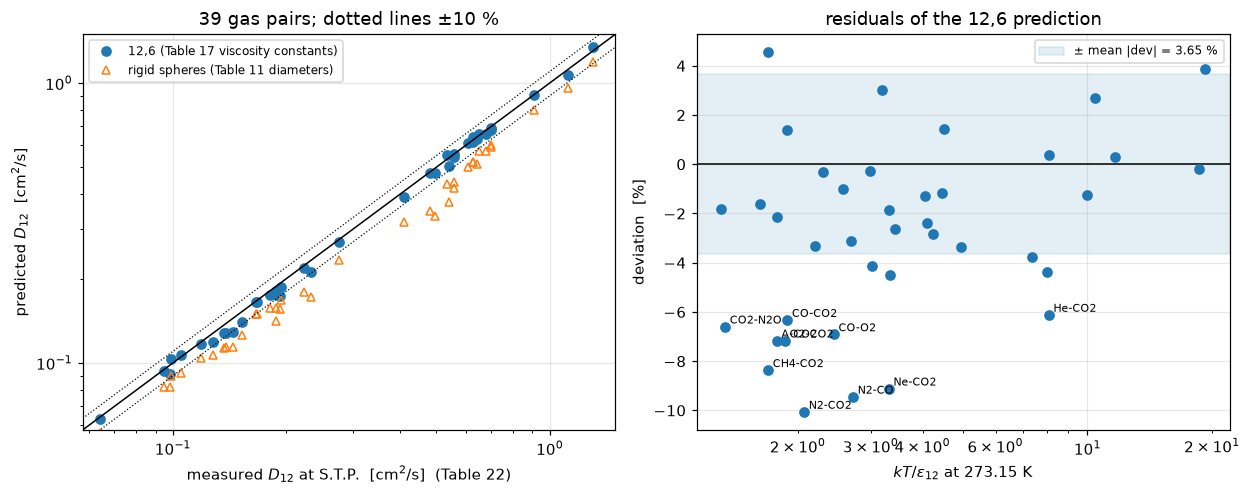

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax[0].loglog(meas, tab.sort_index()["D_12,6"], "o", ms=6, label="12,6 (Table 17 viscosity constants)")
ax[0].loglog(meas, [CE.d12_first(a, b, W=1.0, sig=SIG11) for a, b, _ in USABLE], "^", ms=5,
             mfc="none", label="rigid spheres (Table 11 diameters)")
lim = [0.9 * meas.min(), 1.15 * meas.max()]
ax[0].plot(lim, lim, "k-", lw=1)
for f in (1.1, 0.9):
    ax[0].plot(lim, [f * v for v in lim], "k:", lw=0.8)
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("measured $D_{12}$ at S.T.P.  [cm$^2$/s]  (Table 22)")
ax[0].set_ylabel("predicted $D_{12}$  [cm$^2$/s]")
ax[0].set_title(f"{len(USABLE)} gas pairs; dotted lines $\\pm$10 %")
ax[0].legend(fontsize=8, loc="upper left")

ax[1].axhline(0, color="k", lw=1)
ax[1].semilogx(Tstar, res_126["dev"], "o", ms=6)
for x, y, lab in zip(Tstar, res_126["dev"], [f"{a}-{b}" for a, b, _ in USABLE]):
    if abs(y) > 6:
        ax[1].annotate(lab, (x, y), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax[1].axhspan(-res_126["mean_abs"], res_126["mean_abs"], color="C0", alpha=0.12,
              label=f"$\\pm$ mean |dev| = {res_126['mean_abs']:.2f} %")
ax[1].set_xlabel("$kT/\\varepsilon_{12}$ at 273.15 K")
ax[1].set_ylabel("deviation  [%]")
ax[1].set_title("residuals of the 12,6 prediction")
ax[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Validation

Ranked by what each check can actually catch. The first is the only one that
tests the *physics*; the rest test the transcription, the numerics, or an
identity, and each says which.

### 1. An independent computation of the collision integrals

The single largest risk on this page is that Table 6 has been mis-read, since
every predicted $D_{12}$ is inversely proportional to it. So
$\Omega^{(1,1)*}$ and $\Omega^{(2,2)*}$ are **recomputed from the 12,6 potential
by quadrature**, with no reference to Table 6 at all: the classical deflection
angle

$$
\chi(b,E) = \pi - 2b\!\!\int_{r_0}^{\infty}\!\!
\frac{\mathrm{d}r}{r^2\sqrt{1 - b^2/r^2 - V(r)/E}}
$$

integrated over impact parameter to give the transport cross-sections, then over
a Maxwellian energy distribution. The turning point $r_0$ is the outermost root
of the expression under the square root; multiplied by $r^{12}$ it is a sextic
in $r^2$, whose roots are found all at once as the eigenvalues of its companion
matrix (the largest real one is $r_0$; by Descartes' rule there are one or three
positive roots). The inverse-square-root singularity at $r_0$ is removed by the
substitution $u = r_0/r = 1 - s^2$, which turns $\mathrm{d}u/\sqrt{f}$ into a
regular integrand. The quadrature's own error is measured row by row: each of
its four knobs (energy points, impact-parameter points, radial points, and the
impact-parameter cut-off) is refined in turn, and the largest change is the
row's error estimate.

This is a genuinely independent route, and it settles three things at once: it
checks the transcription, it establishes the illegible $\tfrac12$ in Table 6's
header, and it gives a **second, table-free path to every $D_{12}$ on the page**.

### 2. Four printed-table round trips

Already run under *The data*. Each relates two columns the book printed
separately, so a mis-read digit in either breaks it.

### 3. The printed limits of the second approximation

Section 14.3 states four exact results for the composition dependence, and they
are strong tests of eqs. (14.21, 2–6) because the transcription of six equations
has to be right for any of them to come out:

- $\Delta_1 = m_1^2/(13m_1^2 + 30m_2^2 + 16m_1m_2)$ for rigid spheres
  (eq. 14.3, 2);
- $\Delta_1 \to 1/13$ as $m_2/m_1 \to 0$, so the end-to-end variation of
  $[D_{12}]_2$ is $13/12$, "8⅓ per cent";
- the Kihara approximation $\mathrm{B} = \tfrac34$ gives "1/9, or 11·1 per cent";
- $[D_{12}]_2 = 1.083\,[D_{12}]_1$ in the Lorentz limit (§14.21, from Table 7).

The rigid-sphere constants they need are not fitted either: eq. (10.2, 1) gives
$\mathscr{W}^{(l)}(r)$ in closed form, so (9.8, 7) yields
A = 2/5, B = 3/5, C = 1/5 exactly. The limits are taken in closed form: pure
gas 1 is $x_1 = 1$, and the Lorentz limit is $M_2 = 0$.

### 4. Defect injection

Every number the page states is a registered claim with a row in the break
table at the end of this section that fails its check.

In [13]:
# ---- independent quadrature of the 12,6 collision integrals ------------------
T6 = tuple(float(T) for T in t6.kT_over_eps12)
QUAD = dict(n_E=72, n_b=120, n_panel=6, b_max=6.0, n_g=96)
PAIR_RANGE = (float(Tstar.min()), float(Tstar.max()))


@lru_cache(maxsize=None)
def quad_at(ts, n_E, n_b, n_panel, b_max, n_g):
    """(Omega11*, Omega22*) at each kT/eps in ``ts``; cached by its knobs."""
    return np.array([omega_11_22(T, n_E=n_E, n_b=n_b, n_panel=n_panel, b_max=b_max, n_g=n_g)
                     for T in ts])


def refinements(kw):
    """The four knob refinements of a quadrature: each knob alone."""
    return [dict(kw, n_E=2 * kw["n_E"]), dict(kw, n_b=2 * kw["n_b"]), dict(kw, n_g=2 * kw["n_g"]),
            dict(kw, b_max=kw["b_max"] * 4 / 3, n_panel=kw["n_panel"] + 2)]


def quad_study(header=0.5, w11=t6.W11.values, **knobs):
    """Quadrature against Table 6, with the quadrature's own error per row.

    ``header`` is the fraction read in Table 6's third-column header.
    """
    kw = {**QUAD, **knobs}
    q = quad_at(T6, **kw)
    err = 100 * np.max([np.abs(quad_at(T6, **r) / q - 1) for r in refinements(kw)], axis=0)
    col = np.column_stack([w11, t6.W22_half.values / (2 * header)])   # W11 and W22(2)/2
    gap = 100 * np.abs(q / col - 1)
    worst = int(gap[:, 0].argmax())                                     # a named table row
    t = np.array(T6)
    lo = t[t <= PAIR_RANGE[0]].max()                                    # rows bracketing the pairs
    hi = t[t >= PAIR_RANGE[1]].min()
    rng = (t >= lo) & (t <= hi)
    # joint refinement: n_E and n_b doubled together; refined: n_E x4, n_b x2, n_panel x2
    joint = dict(kw, n_E=2 * kw["n_E"], n_b=2 * kw["n_b"])
    fine = dict(kw, n_E=4 * kw["n_E"], n_b=2 * kw["n_b"], n_panel=2 * kw["n_panel"])
    low = {}
    for name, T in (("T05", 0.5), ("T03", 0.3)):
        i = T6.index(T)
        qj = quad_at((T,), **joint)[0]
        qf = quad_at((T,), **fine)[0]
        low[f"quad_joint_change_at_{name}_pct"] = float(100 * np.max(np.abs(qj / q[i] - 1)))
        low[f"omega_gap_at_{name}_refined_pct"] = float(100 * np.max(np.abs(qf / col[i] - 1)))
    return {**low, "omega11_quad_vs_t6_max_pct": float(gap[:, 0].max()),
            "omega22_quad_vs_t6_half_max_pct": float(gap[:, 1].max()),
            "quad_refinement_max_pct": float(err.max()),
            "quad_refinement_at_worst_row_pct": float(err[worst].max()),
            "quad_refinement_pair_range_pct": float(err[rng].max()),
            "omega_gap_at_T05_pct": float(gap[T6.index(0.5)].max()),
            "omega_gap_at_T03_pct": float(gap[T6.index(0.3)].max()),
            "_q": q, "_err": err, "_gap": gap, "_worst": worst, "_rng": (lo, hi)}


QS = quad_study()
q6, gap6, err6 = QS["_q"], QS["_gap"], QS["_err"]
print(f"{'kT/eps':>8}{'O11 quad':>10}{'Table 6':>10}{'gap %':>8}{'quad err %':>11}   "
      f"{'O22 quad':>10}{'col.3':>9}{'gap %':>8}{'quad err %':>11}")
for i, T in enumerate(T6):
    print(f"{T:>8.1f}{q6[i, 0]:>10.4f}{t6.W11.values[i]:>10.4f}{gap6[i, 0]:>8.3f}{err6[i, 0]:>11.1e}   "
          f"{q6[i, 1]:>10.4f}{t6.W22_half.values[i]:>9.4f}{gap6[i, 1]:>8.3f}{err6[i, 1]:>11.1e}")
big = [T6[i] for i in range(len(T6)) if gap6[i].max() > 0.1]
print(f"rows where a gap exceeds 0.1 %: kT/eps = {big}")
print(f"rows where a gap exceeds three times the quadrature's own error: kT/eps = "
      f"{[T6[i] for i in range(len(T6)) if gap6[i].max() > 3 * err6[i].max()]}")

  kT/eps  O11 quad   Table 6   gap % quad err %     O22 quad    col.3   gap % quad err %
     0.3    2.6479    2.6480   0.004    9.3e-02       2.8420   2.8410   0.037    6.7e-02
     0.5    2.0696    2.0660   0.174    1.6e-01       2.2866   2.2840   0.115    9.6e-02
     0.7    1.7297    1.7290   0.042    4.1e-02       1.9218   1.9220   0.009    2.6e-02
     1.0    1.4393    1.4400   0.052    8.3e-02       1.5937   1.5930   0.044    4.4e-02
     1.3    1.2738    1.2740   0.014    1.4e-02       1.4016   1.4010   0.040    1.8e-03
     1.6    1.1682    1.1680   0.019    3.9e-02       1.2800   1.2800   0.003    1.1e-02
     2.0    1.0748    1.0750   0.020    4.8e-02       1.1758   1.1760   0.014    2.8e-03
     2.5    1.0007    1.0002   0.053    4.6e-03       1.0933   1.0930   0.032    5.8e-03
     3.0    0.9498    0.9500   0.016    1.5e-02       1.0389   1.0388   0.006    8.9e-04
     4.0    0.8847    0.8845   0.025    1.2e-02       0.9699   0.9699   0.003    1.6e-03
     5.0    0.8428   

In [14]:
w = QS["_worst"]
display(Markdown(f"""
The quadrature reproduces Table 6's $\\mathscr{{W}}^{{(1)}}_{{12}}(1)$ to
**{QS['omega11_quad_vs_t6_max_pct']:.2f} %** at worst over all {len(T6)} rows, and the third column to
**{QS['omega22_quad_vs_t6_half_max_pct']:.2f} %** if that column is $\\tfrac12\\mathscr{{W}}^{{(2)}}_{{12}}(2)$.
Read as $\\tfrac13$, the third column misses the quadrature by tens of per cent (a row of the break
table). The illegible fraction is a $\\tfrac12$, on two independent grounds: this quadrature, and
eq. (9.8, 7)'s A identity below.

Both worst cases sit on the **same** row, $kT/\\varepsilon_{{12}} = {T6[w]:.0f}$, and there the
quadrature is *converged*: refining each of its knobs moves it by at most
{QS['quad_refinement_at_worst_row_pct']:.1e} %. So that residual is a difference between two
numerical integrations of the same integral rather than an error in this one: Table 6 is Monchick &
Mason's and Itean, Glueck & Svehla's machine integration, and this page does not claim to
adjudicate.

The hard rows are the lowest, where the 12,6 potential *orbits* and the classical deflection
integral diverges at a critical impact parameter; panelling the $b$ integral brings them in, but
there the quadrature's own refinement moves the answer by up to
{QS['quad_refinement_max_pct']:.2f} %, as much as its gap to the table, so those rows test the
transcription only to that level: at kT/eps = 0.5 the gap is {QS['omega_gap_at_T05_pct']:.3f} %. Doubling $n_E$ and $n_b$ together moves
that row by {QS['quad_joint_change_at_T05_pct']:.3f} %, more than either knob alone, so the gap is the
production quadrature's own error: refined ($n_E$ x4, $n_b$ x2, panels x2) the gap is
{QS['omega_gap_at_T05_refined_pct']:.3f} %. At kT/eps = 0.3 the production gap is
{QS['omega_gap_at_T03_pct']:.3f} %, the joint doubling moves it by {QS['quad_joint_change_at_T03_pct']:.3f} %
and the refined gap is {QS['omega_gap_at_T03_refined_pct']:.3f} %. A gap exceeds three times the quadrature's own error only
on the rows printed above. The pairs on this page have $kT/\\varepsilon_{{12}}$ between
{PAIR_RANGE[0]:.2f} and {PAIR_RANGE[1]:.1f}, above the orbiting rows; on the Table 6 rows that
bracket that range (kT/eps from {QS['_rng'][0]:g} to {QS['_rng'][1]:g}) the quadrature's own error
is up to {QS['quad_refinement_pair_range_pct']:.3f} %, which limits how finely the second route
below can test the table there.
"""))


The quadrature reproduces Table 6's $\mathscr{W}^{(1)}_{12}(1)$ to
**0.18 %** at worst over all 16 rows, and the third column to
**0.30 %** if that column is $\tfrac12\mathscr{W}^{(2)}_{12}(2)$.
Read as $\tfrac13$, the third column misses the quadrature by tens of per cent (a row of the break
table). The illegible fraction is a $\tfrac12$, on two independent grounds: this quadrature, and
eq. (9.8, 7)'s A identity below.

Both worst cases sit on the **same** row, $kT/\varepsilon_{12} = 100$, and there the
quadrature is *converged*: refining each of its knobs moves it by at most
3.5e-05 %. So that residual is a difference between two
numerical integrations of the same integral rather than an error in this one: Table 6 is Monchick &
Mason's and Itean, Glueck & Svehla's machine integration, and this page does not claim to
adjudicate.

The hard rows are the lowest, where the 12,6 potential *orbits* and the classical deflection
integral diverges at a critical impact parameter; panelling the $b$ integral brings them in, but
there the quadrature's own refinement moves the answer by up to
0.16 %, as much as its gap to the table, so those rows test the
transcription only to that level: at kT/eps = 0.5 the gap is 0.174 %. Doubling $n_E$ and $n_b$ together moves
that row by 0.211 %, more than either knob alone, so the gap is the
production quadrature's own error: refined ($n_E$ x4, $n_b$ x2, panels x2) the gap is
0.037 %. At kT/eps = 0.3 the production gap is
0.037 %, the joint doubling moves it by 0.091 %
and the refined gap is 0.097 %. A gap exceeds three times the quadrature's own error only
on the rows printed above. The pairs on this page have $kT/\varepsilon_{12}$ between
1.31 and 19.3, above the orbiting rows; on the Table 6 rows that
bracket that range (kT/eps from 1.3 to 20) the quadrature's own error
is up to 0.048 %, which limits how finely the second route
below can test the table there.


In [15]:
# ---- the second, table-free route to every D12 -------------------------------
PAIR_TS = tuple(sorted({round(float(T), 10) for T in Tstar}))


def route_study(w11=t6.W11.values, **knobs):
    """Every D12 with Table 6 against every D12 with the quadrature's Omega11*."""
    kw = {**QUAD, **knobs}
    ce = make_ce(w11=w11)
    om = dict(zip(PAIR_TS, quad_at(PAIR_TS, **kw)[:, 0]))
    d_tab = np.array([ce.d12_first(a, b) for a, b, _ in USABLE])
    d_qua = np.array([ce.d12_first(a, b, W=om[round(float(T), 10)]) for (a, b, _), T in zip(USABLE, Tstar)])
    rq = dev_stats(d_qua, meas)
    return {"d12_two_routes_max_pct": float(100 * np.abs(d_qua / d_tab - 1).max()),
            "d12_quadrature_route_mean_abs_pct": rq["mean_abs"],
            "_rms": float(100 * np.sqrt(np.mean((d_qua / d_tab - 1) ** 2))), "_rq": rq}


RS = route_study()
print(f"{len(PAIR_TS)} distinct kT/eps values among the pairs")
display(Markdown(f"""
**The headline computed a second, independent way.** Replacing Table 6 entirely by the quadrature
above changes each predicted $D_{{12}}$ by at most **{RS['d12_two_routes_max_pct']:.3f} %**
(r.m.s. {RS['_rms']:.3f} %), and moves the headline from
{res_126['mean_abs']:.3f} % to **{RS['d12_quadrature_route_mean_abs_pct']:.3f} %** mean absolute
deviation, bias {res_126['bias']:+.3f} % to {RS['_rq']['bias']:+.3f} %. The two routes share the
masses, the force constants, the combination rules and the state, but not the collision integrals,
which are the part that could have been mis-transcribed. **A perturbation test could not have
established this**: it shows the answer is sensitive to Table 6, not that Table 6 was read correctly.
"""))

36 distinct kT/eps values among the pairs



**The headline computed a second, independent way.** Replacing Table 6 entirely by the quadrature
above changes each predicted $D_{12}$ by at most **0.066 %**
(r.m.s. 0.026 %), and moves the headline from
3.647 % to **3.655 %** mean absolute
deviation, bias -2.744 % to -2.755 %. The two routes share the
masses, the force constants, the combination rules and the state, but not the collision integrals,
which are the part that could have been mis-transcribed. **A perturbation test could not have
established this**: it shows the answer is sensitive to Table 6, not that Table 6 was read correctly.


In [16]:
# ---- Table 6's internal identities ------------------------------------------
# (9.8, 7):  A = Omega^(2)(2) / 5 Omega^(1)(1);  (10.2, 1): W^(1)(1) = 1, W^(2)(2) = 2 for
# rigid spheres, so with column 3 = header * W^(2)(2):  A = col3 / (5 * header * col1).
# (14.4, 1):  dln[D12]_1/dlnT = 2 - (5/2)C, and [D12]_1 ~ T^(3/2)/W, so
#             dln W / dln T* = (5/2)C - 1/2.
def t6_study(w11=t6.W11.values, header=0.5):
    """Table 6's A column against eq. (9.8, 7), and its C column against eq. (14.4, 1)."""
    col3, A = t6.W22_half.values, t6.A.values
    rel = col3 / (5 * header * w11) / A - 1
    allow = (half_unit(s6.A) / A + half_unit(s6.W22_half) / col3 + half_unit(s6.W11) / w11)
    slope = CollisionTable(t6.kT_over_eps12.values, w11, A, t6.B.values, t6.C.values).spl_w(
        np.log(t6.kT_over_eps12.values), 1)
    d = slope - (2.5 * t6.C.values - 0.5)
    return {"t6_A_identity_max_rel": float(np.abs(rel).max()),
            "t6_A_identity_max_over_rounding": float(np.max(np.abs(rel) / allow)),
            "t6_C_vs_dlnW_rms": float(np.sqrt(np.mean(d ** 2))), "_d": d}


TS6 = t6_study()
print(f"(9.8,7)  A = 2*col3/(5*col1): max rel dev {TS6['t6_A_identity_max_rel']:.2e}, "
      f"{TS6['t6_A_identity_max_over_rounding']:.2f} of its rounding allowance")
print(f"(14.4,1) dlnW/dlnT* vs (5/2)C - 1/2: rms {TS6['t6_C_vs_dlnW_rms']:.4f}, "
      f"max {np.abs(TS6['_d']).max():.4f} over {len(t6)} rows "
      f"({np.abs(TS6['_d'][1:-1]).max():.4f} excluding the two spline end rows)")


# ---- the printed limits of the second approximation -------------------------
def limits_study(A_rs=2 / 5, B_rs=3 / 5, C_rs=1 / 5, B_kihara=3 / 4):
    """Section 14.3's exact results, with the limits taken in closed form."""
    worst = 0.0
    for mr in (1.0, 2.0, 3.0, 10.0, 100.0):
        M1, M2 = mr / (mr + 1), 1 / (mr + 1)
        got = delta_generic(1.0, M1, M2, 1.0, 1.0, A_rs, B_rs, C_rs)
        worst = max(worst, abs(got / (mr ** 2 / (13 * mr ** 2 + 30 + 16 * mr)) - 1))
    d1 = delta_generic(1.0, 1.0, 0.0, 1.0, 1.0, A_rs, B_rs, C_rs)        # pure gas 1, M2 = 0
    d2 = delta_generic(0.0, 1.0, 0.0, 1.0, 1.0, A_rs, B_rs, C_rs)        # pure gas 2, M2 = 0
    d1k = delta_generic(1.0, 1.0, 0.0, 1.0, 1.0, A_rs, B_kihara, C_rs)
    d2k = delta_generic(0.0, 1.0, 0.0, 1.0, 1.0, A_rs, B_kihara, C_rs)
    return {"eq1432_max_rel": float(worst), "lorentz_D2_over_D1": float(1 / (1 - d1)),
            "lorentz_variation_pct": float(100 * ((1 - d2) / (1 - d1) - 1)),
            "kihara_variation_pct": float(100 * ((1 - d2k) / (1 - d1k) - 1)), "_d1": float(d1)}


LS = limits_study()
print(f"\n(14.3,2) rigid-sphere Delta_1, five mass ratios : max rel dev {LS['eq1432_max_rel']:.2e}")
print(f"Lorentz limit Delta_1 = {LS['_d1']:.10f}  (printed 1/13 = {1/13:.10f})")
print(f"[D12]_2/[D12]_1 = {LS['lorentz_D2_over_D1']:.6f}   (printed 1.083)")
print(f"end-to-end variation = {LS['lorentz_variation_pct']:.4f} %   (printed 8 1/3 % = {100/12:.4f} %)")
print(f"Kihara B = 3/4        = {LS['kihara_variation_pct']:.4f} %   (printed 1/9 = {100/9:.4f} %)")

(9.8,7)  A = 2*col3/(5*col1): max rel dev 2.93e-04, 1.00 of its rounding allowance
(14.4,1) dlnW/dlnT* vs (5/2)C - 1/2: rms 0.0037, max 0.0129 over 16 rows (0.0061 excluding the two spline end rows)

(14.3,2) rigid-sphere Delta_1, five mass ratios : max rel dev 2.22e-16
Lorentz limit Delta_1 = 0.0769230769  (printed 1/13 = 0.0769230769)
[D12]_2/[D12]_1 = 1.083333   (printed 1.083)
end-to-end variation = 8.3333 %   (printed 8 1/3 % = 8.3333 %)
Kihara B = 3/4        = 11.1111 %   (printed 1/9 = 11.1111 %)


In [17]:
# ---- composition dependence of the real pairs, against the book's own bound ---
def composition_study(A=None, B=None, C=None, swap_masses=False):
    """End-to-end swing of [D12]_2 over x1 in [0, 1] for every pair.

    Delta is a ratio of quadratics in x1, so its extrema inside (0, 1) are roots
    of the polynomial num' den - num den'; the swing is max/min of [D12]_2 over
    those roots and the two pure-gas ends (the variation); the end-to-end
    swing compares the two pure-gas ends only.
    """
    swing, var, rise, interior = [], [], [], 0
    for a, b, _ in USABLE:
        num, den = delta_polynomials(*CE.delta_args(a, b, A=A, B=B, C=C, swap_masses=swap_masses))
        r = (num.deriv() * den - num * den.deriv()).roots()
        r = [x.real for x in np.atleast_1d(r) if abs(x.imag) < 1e-12 and 0.0 < x.real < 1.0]
        interior += len(r)
        xs = np.array([0.0, 1.0] + r)
        dd = 1.0 / (1.0 - num(xs) / den(xs))                  # [D12]_2 / [D12]_1
        swing.append(100 * abs(dd[1] / dd[0] - 1))            # end to end
        var.append(100 * (dd.max() / dd.min() - 1))            # over the whole range
        heavy_is_1 = M[a] > M[b]
        rise.append(100 * (dd[1 if heavy_is_1 else 0] / dd[0 if heavy_is_1 else 1] - 1))
    swing, var, rise = np.array(swing), np.array(var), np.array(rise)
    i, j = int(swing.argmax()), int(var.argmax())              # named pairs
    return {"composition_swing_max_pct": float(swing.max()),
            "composition_swing_max_pair": f"{USABLE[i][0]}-{USABLE[i][1]}",
            "composition_variation_max_pct": float(var.max()),
            "composition_variation_max_pair": f"{USABLE[j][0]}-{USABLE[j][1]}",
            "_swing": swing, "_var": var, "_rise": rise, "_interior": interior, "_i": i}


CO = composition_study()
sw, i = CO["_swing"], CO["_i"]
mr = np.array([max(M[a], M[b]) / min(M[a], M[b]) for a, b, _ in USABLE])
UNEQUAL = mr > 1.01                    # the direction is a mass effect: pairs of unequal mass
print(f"interior extrema of Delta over all pairs: {CO['_interior']}; "
      f"pairs with a mass ratio above 1.01: {UNEQUAL.sum()} of {len(USABLE)}")
display(Markdown(f"""
Section 14.3 ends: "for actual gases the variation of $D_{{12}}$ with composition is unlikely to
exceed **about 6 per cent**". Over the {len(USABLE)} pairs the second approximation gives a maximum
end-to-end swing of **{sw.max():.2f} %** ({CO['composition_swing_max_pair']}, mass ratio
{mr[i]:.1f}), mean {sw.mean():.2f} %. Delta has an extremum inside the composition range for
{CO['_interior']} of the pairs, so the full variation over the range can exceed the end-to-end
swing: its maximum is **{CO['composition_variation_max_pct']:.2f} %**
({CO['composition_variation_max_pair']}), the same ends as the largest swing measured on the
light end's value. For {int((CO['_rise'][UNEQUAL] > 0).sum())} of the
{UNEQUAL.sum()} pairs of unequal mass the direction is the one §14.3 predicts: $D_{{12}}$ rises
with the concentration of the *heavier* molecule. The bound holds, and it is a real check: it is
an inequality the computation could have violated.
"""))

interior extrema of Delta over all pairs: 2; pairs with a mass ratio above 1.01: 37 of 39



Section 14.3 ends: "for actual gases the variation of $D_{12}$ with composition is unlikely to
exceed **about 6 per cent**". Over the 39 pairs the second approximation gives a maximum
end-to-end swing of **3.28 %** (He-Kr, mass ratio
20.9), mean 1.30 %. Delta has an extremum inside the composition range for
2 of the pairs, so the full variation over the range can exceed the end-to-end
swing: its maximum is **3.39 %**
(He-Kr), the same ends as the largest swing measured on the
light end's value. For 37 of the
37 pairs of unequal mass the direction is the one §14.3 predicts: $D_{12}$ rises
with the concentration of the *heavier* molecule. The bound holds, and it is a real check: it is
an inequality the computation could have violated.


## What pymrm adds

Everything above is algebra. Here is the part that needs a solver.

Chapman & Cowling are explicit that they set the composition dependence aside
when interpreting the data (§14.31, just before the §14.32 heading on the same page): *"Since the error in the first
approximation to the coefficient of diffusion is not very large, it is ignored
in the subsequent discussion. This implies that the variation of $D_{12}$ with
the proportions of a mixture is ignored."* The alternative was a nonlinear PDE.

But the apparatus that produced many of the Table 22 numbers is a **closed
tube whose composition runs from 0 to 1 across its own length**. So the
question the book cannot answer is: *when a Loschmidt cell is analysed with the
constant-$D$ formula, which $D$ does it report?* $[D_{12}]_1$? The equimolar
$[D_{12}]_2$? Something else?

pymrm answers it directly. Solve the cell with $D_{12} = [D_{12}]_2(x_1)$, take
the observable the experiment actually reports (the difference in mean
composition between the two halves at the moment of separation) and invert the
**constant-$D$** closed form for the apparent $D$, exactly as the experimenter
would; the inversion is a root of the closed form on the physical range of $D$,
found by `pymrm.checks.find_roots`, which must return exactly one. Three pairs
are run, spanning the mass disparity that drives the effect, and one of them
(N₂–CO, almost equal masses) is a **control that must show nothing**. The
apparent excess over $[D_{12}]_1$ is computed against a constant-$D$ cell on the
same grid and step, and extrapolated to zero cell size and zero step (the
ladders were printed under *PyMRM implementation*).

In [18]:
rows = []
for g1, g2 in CASES:
    t = f"{g1}{g2}"
    rows.append(dict(pair=f"{g1}-{g2}", m_ratio=max(M[g1], M[g2]) / min(M[g1], M[g2]),
                     D1=CE.d12_first(g1, g2), eq_pct=CS[f"cell_equimolar_excess_pct_{t}"],
                     app_pct=CS[f"cell_apparent_excess_pct_{t}"]))
ap = pd.DataFrame(rows)
ap["shortfall_pp"] = ap.eq_pct - ap.app_pct
print(ap.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"largest correction of the extrapolation (production level against extrapolated): "
      f"{CS['cell_excess_discretisation_pp']:.1e} pp")

 pair  m_ratio     D1  eq_pct  app_pct  shortfall_pp
He-Xe  32.8004 0.4773  2.6767   2.5275        0.1492
H2-N2  13.8953 0.6553  1.8908   1.8036        0.0872
N2-CO   1.0001 0.1739  0.3127   0.3128       -0.0001
largest correction of the extrapolation (production level against extrapolated): 2.9e-03 pp


In [19]:
display(Markdown(f"""
**The answer.** A Loschmidt cell run on the second approximation reports an apparent diffusivity
**{ap.app_pct[0]:.2f} % above $[D_{{12}}]_1$** for He–Xe, {ap.app_pct[1]:.2f} % for H₂–N₂, and
{ap.app_pct[2]:.2f} % for the equal-mass control N₂–CO. It is *not* the equimolar second
approximation: that gives {ap.eq_pct[0]:.2f} %, {ap.eq_pct[1]:.2f} % and {ap.eq_pct[2]:.2f} %, so the
cell falls short by {ap.shortfall_pp[0]:.3f}, {ap.shortfall_pp[1]:.3f} and
{ap.shortfall_pp[2]:.4f} percentage points respectively: the shortfall grows with the mass ratio,
and vanishes for the control, which is what it must do.

Two consequences, and the second is the useful one.

1. **The neglect §14.32 makes is worth {ap.app_pct[0]:.1f} % at the extreme of this dataset.** That
   is comfortably inside the "several per cent" experimental error the same section quotes, so
   Chapman & Cowling's decision to ignore it was correct, but here it is *measured* rather than
   assumed, and it is not negligible next to the {res_126['mean_abs']:.1f} % headline: it is roughly
   {ap.app_pct[0]/res_126['mean_abs']*100:.0f} % of it.
2. **The reported $D_{{12}}$ of a transient cell is a weighted average over a composition history,
   not a value at a stated composition.** Anyone comparing a measured $D_{{12}}$ against
   $[D_{{12}}]_2$ at some nominal $x_1$ is comparing two different quantities, and for a mass ratio
   as large as He–Xe's the difference is resolvable. The pymrm solve gives the mapping without needing
   the composition to be recorded, which §14.32 says it often was not.

**What this does not establish.** The cell is a *model* of the apparatus, not the apparatus: it is
one-dimensional, isothermal, with a perfect initial step and no convection, and the real
instruments in Table 22's references include two-bulb cells and evaporation tubes with different
geometries. The number above is what the second approximation implies for an idealised Loschmidt
tube, and nothing more. It is not a correction that should be applied to Table 22.
"""))


**The answer.** A Loschmidt cell run on the second approximation reports an apparent diffusivity
**2.53 % above $[D_{12}]_1$** for He–Xe, 1.80 % for H₂–N₂, and
0.31 % for the equal-mass control N₂–CO. It is *not* the equimolar second
approximation: that gives 2.68 %, 1.89 % and 0.31 %, so the
cell falls short by 0.149, 0.087 and
-0.0001 percentage points respectively: the shortfall grows with the mass ratio,
and vanishes for the control, which is what it must do.

Two consequences, and the second is the useful one.

1. **The neglect §14.32 makes is worth 2.5 % at the extreme of this dataset.** That
   is comfortably inside the "several per cent" experimental error the same section quotes, so
   Chapman & Cowling's decision to ignore it was correct, but here it is *measured* rather than
   assumed, and it is not negligible next to the 3.6 % headline: it is roughly
   69 % of it.
2. **The reported $D_{12}$ of a transient cell is a weighted average over a composition history,
   not a value at a stated composition.** Anyone comparing a measured $D_{12}$ against
   $[D_{12}]_2$ at some nominal $x_1$ is comparing two different quantities, and for a mass ratio
   as large as He–Xe's the difference is resolvable. The pymrm solve gives the mapping without needing
   the composition to be recorded, which §14.32 says it often was not.

**What this does not establish.** The cell is a *model* of the apparatus, not the apparatus: it is
one-dimensional, isothermal, with a perfect initial step and no convection, and the real
instruments in Table 22's references include two-bulb cells and evaporation tubes with different
geometries. The number above is what the second approximation implies for an idealised Loschmidt
tube, and nothing more. It is not a correction that should be applied to Table 22.


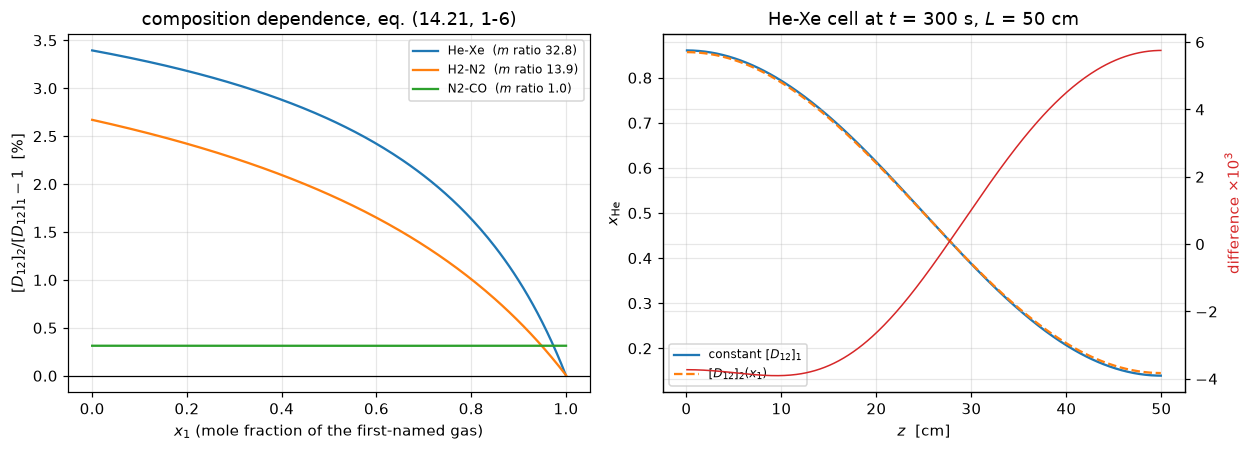

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
xg = np.linspace(0, 1, 201)
for g1, g2 in CASES:
    ax[0].plot(xg, 100 * (CE.d12_second(g1, g2, xg) / CE.d12_first(g1, g2) - 1),
               label=f"{g1}-{g2}  ($m$ ratio {max(M[g1], M[g2])/min(M[g1], M[g2]):.1f})")
ax[0].set_xlabel("$x_1$ (mole fraction of the first-named gas)")
ax[0].set_ylabel("$[D_{12}]_2/[D_{12}]_1 - 1$  [%]")
ax[0].set_title("composition dependence, eq. (14.21, 1-6)")
ax[0].legend(fontsize=8)
ax[0].axhline(0, color="k", lw=0.8)

g1, g2 = CASES[0]
D1 = CE.d12_first(g1, g2)
c_const = DiffusionCell(L_CELL, NS_Z[-1], D1)
c_var = DiffusionCell(L_CELL, NS_Z[-1], lambda x: D1 / (1 - CE.delta(g1, g2, x)), tol=TOL)
x_const, x_var = c_const.solve(T_CELL, NS_T[-1]).ravel(), c_var.solve(T_CELL, NS_T[-1]).ravel()
ax[1].plot(c_const.x_c, x_const, label="constant $[D_{12}]_1$")
ax[1].plot(c_var.x_c, x_var, "--", label="$[D_{12}]_2(x_1)$")
axr = ax[1].twinx()
axr.plot(c_var.x_c, 1e3 * (x_var - x_const), color="C3", lw=1)
axr.set_ylabel("difference $\\times 10^{3}$", color="C3")
ax[1].set_xlabel("$z$  [cm]")
ax[1].set_ylabel("$x_{\\mathrm{He}}$")
ax[1].set_title(f"{g1}-{g2} cell at $t$ = {T_CELL:.0f} s, $L$ = {L_CELL:.0f} cm")
ax[1].legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

### The claims and the defect-injection table

Every number the page states is registered below with how it is checked:
deterministic results as values (held to a relative 1e-6 of the committed
baseline), residuals, two-route gaps, refinement changes and orders as bounds
with their basis, and counts and labels as exact. Each claim then needs a row
that fails its own check. Each row injects one defect through a call argument
(a combination rule, a force constant, the state, a transposed digit in a
table column, the fraction in Table 6's header, the 1.016 correction, a
rigid-sphere constant of the second approximation, a quadrature knob, the
geometry index, the face-composition rule, the time scheme, the Newton
tolerance, the series length, the refinement ladder) and reruns the whole study
the claim comes from. A study that cannot be completed under a defect records
`nan` for its claims.

In [21]:
FIXED = 1e-6
STUDIES = {"state": ST, "roundtrip": RT, "deviation": DS, "quadrature": QS, "route": RS,
           "t6": TS6, "limits": LS, "composition": CO, "cell": CS}
ALL = {k: v for s in STUDIES.values() for k, v in s.items() if not k.startswith("_")}
ROUNDING = "the residual over its rounding allowance (half units of every printed entry involved)"
BOUNDS = {
    "t22_sigma12_bias_z": dict(min=-2.0, max=2.0, basis="theory",
        note="mean signed residual over its standard error: rounding residuals average to zero"),
    "t22_sigma12_max_over_rounding": dict(max=1.0, basis="theory", note=ROUNDING),
    "t17_rm_max_over_rounding": dict(max=1.0, basis="theory", note=ROUNDING),
    "t6_C_vs_dlnW_rms": dict(max=0.01, basis="chosen",
        note="a cubic-spline slope of a printed column against another printed column; a "
             "transposed digit raises it by an order of magnitude or more"),
    "quad_refinement_max_pct": dict(max=0.3, basis="chosen",
        note="largest change of any row under a single-knob refinement; the orbiting rows "
             "at the lowest kT/eps set it"),
    "quad_refinement_at_worst_row_pct": dict(max=1e-3, basis="chosen",
        note="the quadrature at the row of the largest gap to Table 6 is converged far below that gap"),
    "d12_two_routes_max_pct": dict(max=0.1, basis="chosen",
        note="D12 ~ 1/W11, so the gap is the table-against-quadrature gap in the pairs' range"),
    "eq1432_max_rel": dict(max=1e-12, basis="identity", note="eq. (14.3, 2) against eqs. (14.21, 2-6)"),
    "cell_grid_order": dict(min=1.9, max=2.1, basis="theory",
        note="He-Xe apparent excess, finest triple of the cell-size ladder"),
    "cell_time_order": dict(min=0.9, max=1.1, basis="theory",
        note="He-Xe apparent excess, finest triple of the step ladder; backward Euler"),
    "cell_grid_ladder_over_roundoff": dict(min=1e3, basis="theory",
        note="finest successive difference over the excess a split error of the Newton tolerance makes"),
    "cell_time_ladder_over_roundoff": dict(min=1e3, basis="theory",
        note="finest successive difference over the excess a split error of the Newton tolerance makes"),
    "cell_excess_discretisation_pp": dict(max=0.01, basis="theory",
        note="production level against the value extrapolated in both cell size and step"),
    "cell_const_vs_series": dict(max=1e-4, basis="theory",
        note="constant-D split extrapolated in both axes against the cosine series; the "
             "remainder of the extrapolation"),
    "split_series_tail": dict(max=1e-15, basis="theory",
        note="tail bound of the cosine series at the smallest D of the inversion range"),
}
for k, v in ALL.items():
    if k in BOUNDS:
        claims.bound(k, v, **BOUNDS[k])
    elif k in ("d12_worst_pair", "d12_n_pairs", "d12_subset_n_pairs", "composition_swing_max_pair",
               "composition_variation_max_pair", "t11_sigma_from_mu_worst_gas",
               "t22_halfsum_worst_pair"):
        claims.exact(k, v)
    else:
        claims.value(k, v, rtol=FIXED)
claims.count("t22_sigma12_1bar_positive", ST["_res_1bar"], 0.0, min_margin=1e-4,
             note="Table 22 rows whose sigma12 rebuilt at 1 bar exceeds the printed one")
claims.count("d12_within_5pct", DS["_abs_dev"], 5.0, above=False, min_margin=1e-3,
             note="pairs whose |dev| of the 12,6 prediction is below 5 %")
claims.count("d12_within_10pct", DS["_abs_dev"], 10.0, above=False, min_margin=1e-3,
             note="pairs whose |dev| of the 12,6 prediction is below 10 %")
claims.count("d12_rigid_sphere_n_under", DS["_rs_dev"], 0.0, above=False, min_margin=1e-3,
             note="pairs the rigid-sphere null model under-predicts")
claims.count("composition_heavier_rises", CO["_rise"][UNEQUAL], 0.0, min_margin=1e-3,
             note="pairs of unequal mass where [D12]_2 is larger in the pure heavier gas")
claims.count("cell_shortfall_falls_with_mass_ratio", CS["_shortfall_steps"], 0.0, min_margin=1e-3,
             note="steps He-Xe -> H2-N2 -> N2-CO, of 2, where the shortfall falls")
COUNTS = {"t22_sigma12_1bar_positive": (state_study, lambda o: (o["_res_1bar"], 0.0, True)),
          "d12_within_5pct":(deviation_study, lambda o: (o["_abs_dev"], 5.0, False)),
          "d12_within_10pct": (deviation_study, lambda o: (o["_abs_dev"], 10.0, False)),
          "d12_rigid_sphere_n_under": (deviation_study, lambda o: (o["_rs_dev"], 0.0, False)),
          "composition_heavier_rises": (composition_study,
                                        lambda o: (o["_rise"][UNEQUAL], 0.0, True)),
          "cell_shortfall_falls_with_mass_ratio": (cell_study,
                                                   lambda o: (o.get("_shortfall_steps"), 0.0, True))}
print(f"{len(claims.metrics)} claims registered")

80 claims registered


In [22]:
def transposed(arr, i):
    """A copy of a printed column with the last two digits of entry i swapped."""
    a = np.array(arr, float).copy()
    s = f"{a[i]:g}"
    a[i] = float(s[:-2] + s[-1] + s[-2])
    return a


I_AR11 = t11.formula.tolist().index("A")
I_AR17 = t17.formula.tolist().index("A")
BAD_W11 = transposed(t6.W11.values, 6)
NO_AR = ({g: v for g, v in EPS_LJ.items() if g != "A"}, {g: v for g, v in SIG_LJ.items() if g != "A"})
HEXE = (("He", "Xe"),)
ROWS = [
    ("p = 1 bar for 1 atm: state", state_study, dict(p=P_BAR)),
    ("T = 293.15 K for 273.15 K: state", state_study, dict(T=293.15)),
    ("D12 of H2-D2 transposed: state", state_study, dict(d12=transposed(D12_PRINTED, 0))),
    ("r_m of argon transposed: round trips", roundtrip_study, dict(rm=transposed(RM_PRINTED, I_AR17))),
    ("mu of argon transposed: round trips", roundtrip_study, dict(mu=transposed(MU_PRINTED, I_AR11))),
    ("the 1.016 correction dropped: round trips", roundtrip_study, dict(corr=1.0)),
    ("Table 22 half-sum column shifted one row: round trips", roundtrip_study,
     dict(half_col=np.roll(HALF_PRINTED, 1))),
    ("eps12 arithmetic for geometric mean: deviations", deviation_study, dict(eps_rule="arithmetic")),
    ("sigma12 geometric for arithmetic mean: deviations", deviation_study, dict(sig_rule="geometric")),
    ("W11 = 1, collision integral deleted: deviations", deviation_study, dict(W=1.0)),
    ("sigma12 scaled by 1.01: deviations", deviation_study, dict(sig_scale=1.01)),
    ("T = 293.15 K for 273.15 K: deviations", deviation_study, dict(T=293.15)),
    ("p = 1 bar for 1 atm: deviations", deviation_study, dict(n=N_STP * P_BAR / P_ATM)),
    ("eps/k of argon misread 124 -> 12.4: deviations", deviation_study,
     dict(eps={**EPS_LJ, "A": 12.4})),
    ("sigma of argon misread 3.42 -> 3.24: deviations", deviation_study,
     dict(sig={**SIG_LJ, "A": 3.24})),
    ("argon missing from Table 17: deviations", deviation_study, dict(eps=NO_AR[0], sig=NO_AR[1])),
    ("Table 6 column 3 read as 1/3: quadrature", quad_study, dict(header=1 / 3)),
    ("W11 of the kT/eps = 2 row transposed: quadrature", quad_study, dict(w11=BAD_W11)),
    ("n_b = 30 per panel: quadrature", quad_study, dict(n_b=30)),
    ("n_E = 12: quadrature", quad_study, dict(n_E=12)),
    ("W11 of the kT/eps = 2 row transposed: second route", route_study, dict(w11=BAD_W11)),
    ("n_b = 30 per panel: second route", route_study, dict(n_b=30)),
    ("W11 of the kT/eps = 2 row transposed: Table 6 identities", t6_study, dict(w11=BAD_W11)),
    ("Table 6 column 3 read as 1/3: Table 6 identities", t6_study, dict(header=1 / 3)),
    ("rigid-sphere B = 1/2 for 3/5: printed limits", limits_study, dict(B_rs=0.5)),
    ("Kihara B = 0.7 for 3/4: printed limits", limits_study, dict(B_kihara=0.7)),
    ("C = 0 (Maxwellian molecules): composition", composition_study, dict(C=0.0)),
    ("masses swapped inside Delta: composition", composition_study, dict(swap_masses=True)),
    ("C = 0 (Maxwellian molecules): cell", cell_study, dict(C=0.0)),
    ("masses swapped inside Delta: cell", cell_study, dict(swap_masses=True)),
    ("nu = 2 for the slab: He-Xe cell", cell_study, dict(cases=HEXE, nu=2)),
    ("interior face composition from the left cell: He-Xe cell", cell_study,
     dict(cases=HEXE, face_rule="left")),
    ("Crank-Nicolson for backward Euler: He-Xe cell", cell_study, dict(cases=HEXE, theta=0.5)),
    ("Newton tolerance 1e-12 -> 1e-6: He-Xe cell", cell_study, dict(cases=HEXE, tol=1e-6)),
    ("cosine series cut at 2 terms: He-Xe cell", cell_study, dict(cases=HEXE, n_terms=2)),
    ("ladders of 6 to 48 cells and 3 to 24 steps: He-Xe cell", cell_study,
     dict(cases=HEXE, ns=(6, 12, 24, 48), nts=(3, 6, 12, 24))),
]
BASE = {state_study: ST, roundtrip_study: RT, deviation_study: DS, quad_study: QS,
        route_study: RS, t6_study: TS6, limits_study: LS, composition_study: CO,
        cell_study: CS}                         # each study's baseline result
claims.define_rows([r[0] for r in ROWS])
BREAK = []
for row, fn, kw in ROWS:
    keys = [k for k in BASE[fn] if not k.startswith("_")]
    keys += [k for k, (f, _) in COUNTS.items() if f is fn]
    raised = False
    try:
        out = fn(**kw)
    except Exception as exc:                     # noqa: BLE001 - a failed study is a result
        print(f"  {row}: study raised {type(exc).__name__}: {str(exc)[:80]}; its claims record nan")
        raised, out = True, {}
    for k in keys:
        if raised:
            broken = np.nan
        elif k in COUNTS:
            v, thr, above = COUNTS[k][1](out)
            if v is None:
                continue                          # a row run on fewer cases
            broken = int(np.sum(np.asarray(v) > thr) if above else np.sum(np.asarray(v) < thr))
        elif k in out:
            broken = out[k]
        else:
            continue                              # a row run on fewer cases
        BREAK.append((row, k, claims.breaks(row, k, broken)))

bt = pd.DataFrame(BREAK, columns=["row", "claim", "caught"])
caught = bt[bt.caught].groupby("row", sort=False).claim.apply(list)
print(f"{len(ROWS)} rows defined, {bt.row.nunique()} in the table; claims each row fails:")
for row, names in caught.items():
    print(f"  {row}:")
    print("      " + "\n      ".join(textwrap.wrap(", ".join(names), 96)))
idle = [r for r in bt.row.unique() if r not in caught.index]
print(f"\nrows that fail no claim: {idle if idle else 'none'}")
missing = [n for n in claims.metrics if not claims.metrics[n].get("structural")
           and not bt[(bt.claim == n) & bt.caught].shape[0]]
print(f"claims no row fails: {missing if missing else 'none'}")

36 rows defined, 36 in the table; claims each row fails:
  p = 1 bar for 1 atm: state:
      t22_sigma12_bias_z, t22_sigma12_from_D_max_abs, t22_sigma12_max_over_rounding
  T = 293.15 K for 273.15 K: state:
      t22_sigma12_bias_z, t22_sigma12_from_D_max_abs, t22_sigma12_max_over_rounding,
      t22_sigma12_bias_z_1bar
  D12 of H2-D2 transposed: state:
      t22_sigma12_from_D_max_abs, t22_sigma12_max_over_rounding, t22_sigma12_bias_z_1bar,
      t22_sigma12_1bar_positive
  r_m of argon transposed: round trips:
      t17_rm_max_abs, t17_rm_max_over_rounding
  mu of argon transposed: round trips:
      t11_sigma_from_mu_max_rel, t11_sigma_from_mu_max_over_rounding, t11_sigma_from_mu_worst_gas,
      t11_sigma_from_mu_no_corr_max_rel
  the 1.016 correction dropped: round trips:
      t11_sigma_from_mu_max_rel, t11_sigma_from_mu_max_over_rounding, t11_sigma_from_mu_worst_gas
  Table 22 half-sum column shifted one row: round trips:
      t22_halfsum_from_t11_max_abs, t22_halfsum_max_over_

**Reading the tables.**

*The headline is sensitive, and not to a single thing.* Deleting the collision
integral, changing either combination rule, mis-reading one force constant by a
factor of ten, or scaling $\sigma_{12}$ by one per cent all move the mean
deviation outside its tolerance. So the number is not an artefact of an
insensitive metric.

*Two "wrong" choices score better than the published one, and this is stated
rather than buried.* The geometric-mean $\sigma_{12}$ and a 1 bar reference both
give a **lower** mean deviation than the book's own conventions (registered
above as `d12_mean_abs_geometric_sigma_pct` and `d12_mean_abs_1bar_pct`).
Neither is adopted: the arithmetic mean is what eq. (14.2, 1) prints, and 1 atm
is what the book's own $\sigma_{12}$ column requires (established in
*Parameters*, where 1 bar leaves a one-signed bias many standard errors from
zero). But it means the headline sits on a shallow optimum and should be quoted
to one decimal place at most, never as evidence that the conventions are
optimal. **A page that reported the best of those variants would be fitting.**

*The masses enter $[D_{12}]_1$ symmetrically.* Eq. (14.2, 4) is symmetric in
$m_1, m_2$, so $D_{12} = D_{21}$ identically; a swap of the masses can move only
the second approximation, and its rows do.

*What perturbation testing cannot do here.* Every row above shows only that the
answer *depends* on something. None of them shows that the baseline is right:
a consistently mis-transcribed Table 6, or a systematically wrong Loschmidt
number, would move under every perturbation and still be wrong. That is what
the independent quadrature and the four printed round trips are for: they are
the only checks on this page that compare the baseline against something
computed a different way.

## Reuse

**Take the diffusivity, not the page.** `ChapmanEnskog.d12_first(g1, g2, T=..., n=...)`
in `model.py` is the whole Chapman–Enskog result and is the piece worth lifting.
It needs three inputs per gas (molar mass, $\varepsilon/k$, $\sigma$) and the
tabulated $\mathscr{W}^{(1)}_{12}(1)$. Substituting your own force constants is a
change to the `eps` and `sig` dictionaries.

**Quote it with the right error bar.** On this dataset the mean absolute
deviation is a few per cent and the bias is negative: the model tends to
*under*-predict. Two cautions that come out of the numbers above:

- **The accuracy travels with the force constants, not with the theory.**
  Constants fitted to viscosity gave less than half the error of constants
  fitted to virial data on the same pairs. If you take $\varepsilon/k$ and
  $\sigma$ from a compilation, find out what property they were fitted to before
  you quote an accuracy.
- **Do not use it below about $kT/\varepsilon_{12} = 1$ on the strength of this
  page.** Every pair here sits above that, because at 273 K and with Table 17's
  constants none goes lower. Cryogenic or strongly-attracting pairs are outside
  the range tested, and the low-$T^*$ rows of Table 6 are where the quadrature
  is least converged.

**If you need the composition dependence, you need a solver.** `ChapmanEnskog.delta`
and `ChapmanEnskog.d12_second` implement eqs. (14.21, 1–6) and cost nothing extra;
but the moment $D$ depends on composition, an integral relation for the
apparatus no longer inverts in closed form, and `DiffusionCell` is the pattern:
`construct_grad` with zero-flux dictionaries on the outward normal,
`construct_div` with `nu=0`, the face composition from
`construct_boundary_value_matrices` and the interior mean, the face diffusivity
and its derivative placed with `construct_coefficient_matrix`, and `newton`
per backward-Euler step with every step checked. The same skeleton is a Stefan
tube or a two-bulb cell with a different boundary condition.

**What this page deliberately does not do.**

- It does not build the **Fuller–Schettler–Giddings** correlation, which is
  catalogue entry [`A4.5`](../../gallery.qmd) and is an *empirical* estimate of
  the same quantity. The natural comparison (one measured-$D_{12}$ axis with a
  first-principles prediction and an empirical correlation overlaid) is worth
  making, and it should be made on **`A4.5`**, not here: that page has to
  establish its own transcription of the diffusion volumes anyway, and Table 22
  is published on this page in a form it can load cross-page. Building it here
  would mean transcribing `A4.5`'s source without owning it.
- It does not touch **multicomponent** diffusion. Chapter 18 gives the exact
  $n$-component coefficients, but [`A4.2`](../A4.2-maxwell-stefan-vs-fick/index.ipynb)
  and [`A4.9`](../A4.9-duncan-toor/index.ipynb) cover that ground from
  Krishna & Wesselingh and from Duncan & Toor.
- It does not source anything for **`A4.1`** (the Wilke mixture rule). The only
  Wilke in this book is Buddenberg & Wilke (1949) on the *viscosity* of a
  mixture, cited once in §12.43; the 1950 diffusion mixture rule is not stated,
  named or attributed anywhere, so this monograph cannot source a page about it.
- It does not use Table 23. Those force constants are derived from the
  temperature dependence of $D_{12}$ itself, so using them would make the
  comparison circular. That is the trap this page exists to avoid, and it is
  one table away.

**Related pages.** [`A4.2`](../A4.2-maxwell-stefan-vs-fick/index.ipynb)
Maxwell–Stefan against Fick · [`A4.3`](../A4.3-dusty-gas-model/index.ipynb)
dusty gas · [`A4.4`](../A4.4-knudsen-bosanquet/index.ipynb) Knudsen and
Bosanquet, where this $D_{12}$ is the bulk term ·
[`A4.7`](../A4.7-zeolite-micropore-maxwell-stefan/index.ipynb) micropore
Maxwell–Stefan · [`A4.9`](../A4.9-duncan-toor/index.ipynb) Duncan–Toor ternary
diffusion · [`A2.3`](../A2.3-taylor-aris-dispersion/index.ipynb) where a binary
$D$ becomes a dispersion coefficient.

## References

Chapman, S. and Cowling, T. G. (1970). *The Mathematical Theory of Non-Uniform
Gases: An Account of the Kinetic Theory of Viscosity, Thermal Conduction and
Diffusion in Gases*, 3rd edn, prepared in co-operation with D. Burnett.
Cambridge University Press. Reissued in the Cambridge Mathematical Library with
a Foreword by Carlo Cercignani, 1990; reprinted 1993. ISBN 0 521 40844 X.
**The document actually read, and the origin of the result.** Equations
(9.8, 7), (9.8, 8), (9.81, 1), (10.2, 1), (10.42, 1), (12.1, 6), (14.2, 1),
(14.2, 4), (14.21, 1–6), (14.3, 1), (14.3, 2), (14.4, 1) and Tables 6, 11, 17
and 22 were read off cropped renders of the page images on 2026-08-05.

Hirschfelder, J. O., Bird, R. B. and Spotz, E. L. (1948). *J. Chem. Phys.* **16**,
968; *Chem. Rev.* **44** (1949), 205. The origin of most of Table 17's force
constants. **Not consulted**; they reach this page through Table 17, which is
what the book prints and attributes.

Monchick, L. and Mason, E. A. (1961). *J. Chem. Phys.* **35**, 1676; Itean, E. C.,
Glueck, A. R. and Svehla, R. A. (1961). *NASA Report TN D-481*. The numerical
integrations behind Table 6. **Not consulted**; Table 6 is used as printed, and
independently recomputed on this page.

The measurements in Table 22 carry the book's own reference numbers into the
list at the end of its chapter 14; those are kept verbatim in the dataset's
`ref` column. The individual experimental papers were **not consulted**.

In [23]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A4.6:
  t22_sigma12_bias_z                   = (here 4.1e-01)   bound  bound [-2, 2] [theory]
  t22_sigma12_from_D_max_abs           = 0.0050886        value  rtol 1e-06
  t22_sigma12_max_over_rounding        = (here 6.9e-01)   bound  bound <= 1 [theory]
  t22_sigma12_bias_z_1bar              = 34.783           value  rtol 1e-06
  t17_rm_max_abs                       = 0.0051527        value  rtol 1e-06
  t17_rm_max_over_rounding             = (here 4.9e-01)   bound  bound <= 1 [theory]
  t11_sigma_from_mu_max_rel            = 0.00087313       value  rtol 1e-06
  t11_sigma_from_mu_max_over_rounding  = 2.0657           value  rtol 1e-06
  t11_sigma_from_mu_worst_gas          = 'D2'             exact  exact
  t11_sigma_from_mu_no_corr_max_rel    = 0.0087715        value  rtol 1e-06
  t22_halfsum_from_t11_max_abs         = 0.0075           value  rtol 1e-06
  t22_halfsum_max_over_rounding        = 1.3636           value  rtol 1e-06
  t22_halfsum_worst_exact              = 4.287